# Phase 1 - Convolutional Neural Networks

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

Section 5 asks you to run different hyperparameters- please make sure to run all your codes and make sure outputs are neat enough to read.

You may find [this](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) Pytorch tutorial helpful.

## **Overview**
1. Loading & Visualizing Data
2. Utility Functions
3. Define CNNs
4. Train and Evaluate
5. Experiments and Reporting

In [1]:
# Run to import necessary libraries
import time
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(0)
np.random.seed(0)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda:0


# **1. Loading & Visualizing Data**

Please use MNIST for this phase. MNIST is a digit classification dataset, with greyscale 28x28 images, and 10 classes (numbers 0-9).

See [documentation.](https://pytorch.org/vision/0.15/generated/torchvision.datasets.MNIST.html) You can also see the `MNIST_Tutorial.ipynb`.

Please complete loading the data below.

Please also complete `show_imgs()`. Function should input the dataloader, and show 10 random images and their labels.

In [2]:
# MNIST mean/std normalisation (computed over the training set)
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data = datasets.MNIST(root='./data', train=True, download=True, transform=mnist_transform)

test_data = datasets.MNIST(root='./data', train=False, download=True, transform=mnist_transform)

batch_size = 32

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)

test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

print(f'Train samples: {len(train_data)} | Test samples: {len(test_data)}')

Train samples: 60000 | Test samples: 10000


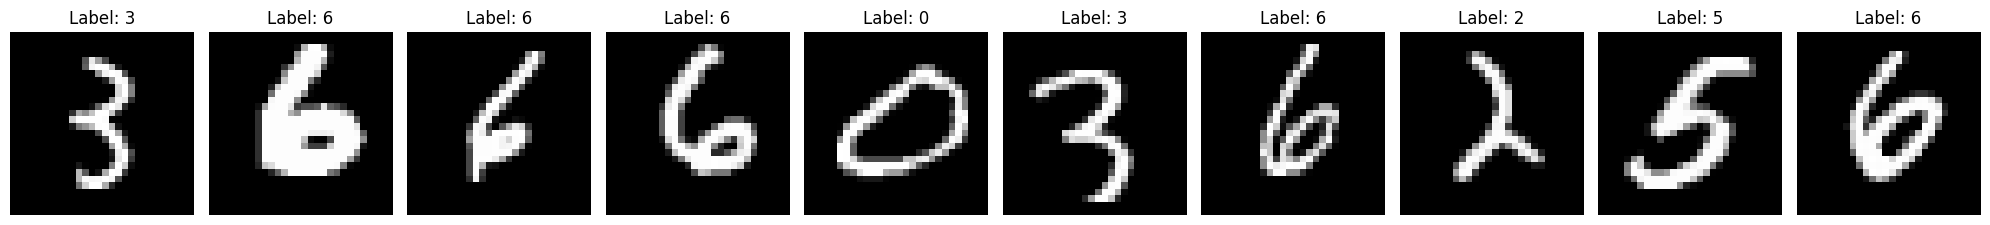

In [3]:
# Function should input the dataloader, and show random 10 images and their labels as title to plot
def show_imgs(dataloader, n=10):
    dataset = dataloader.dataset
    idxs = np.random.choice(len(dataset), n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for ax, idx in zip(axes, idxs):
        img, label = dataset[idx]
        img = img * 0.3081 + 0.1307          # undo normalisation for display
        ax.imshow(img.squeeze().numpy(), cmap='gray')
        ax.set_title(f'Label: {label}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_imgs(train_loader)

## **2. Utility Functions**

Please complete `train()` and `plot_learning_curves()` functions. `test_accuracy()` has already been provided to you.

In [4]:

# hard-coded .cuda(), and always flattened the input, which breaks the CNNs).
# This fixed version keeps the same interface: pass input_size for FC models, or None for CNNs.
def test_accuracy(model, test_loader, input_size=None, device=device):
    model.to(device)
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for test_data in test_loader:
            images, labels = test_data[0].to(device), test_data[1].to(device)
            if input_size is not None:
                images = images.view(-1, input_size)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    acc = 100 * correct / total
    print('Accuracy: %.2f %%' % acc)
    return acc


## **2.1 Train Function**
Please refer to the train function in `MNIST_Classifier.ipynb` to complete this function.
- You will need to store the loss and accuracies per iteration (to plot later). Do this for both the train set and test set!
- Please print the loss, accuracy and time taken **each epoch** for both train and test sets

In [5]:
def evaluate(model, loss_fn, loader, device, input_size=None):
    """Full pass over a loader -> (avg loss, accuracy %)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if input_size is not None:
                images = images.view(-1, input_size)
            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


def train(model, loss_fn, optimizer, train_loader, test_loader, batch_size, num_epochs, device,
          input_size=None):
    """
    Trains `model` and records loss/accuracy PER ITERATION for both train and test.
      - train curve: loss/acc of the mini-batch just trained on
      - test curve : loss/acc on one test mini-batch per iteration (cycled), so we get a
                     cheap per-iteration estimate of generalisation
    Full train/test metrics and time are printed each epoch.
    input_size: set (e.g. 784) to flatten images for FC models; leave None for CNNs.
    """
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': [],
               'epoch_train_loss': [], 'epoch_train_acc': [],
               'epoch_test_loss': [], 'epoch_test_acc': []}
    test_iter = iter(test_loader)

    for epoch in range(num_epochs):
        start = time.time()
        model.train()
        run_loss, run_correct, run_total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            if input_size is not None:
                images = images.view(-1, input_size)

            # forward / backward / step
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            preds = outputs.argmax(1)
            batch_acc = 100 * (preds == labels).float().mean().item()
            history['train_loss'].append(loss.item())
            history['train_acc'].append(batch_acc)
            run_loss += loss.item() * labels.size(0)
            run_correct += (preds == labels).sum().item()
            run_total += labels.size(0)

            # per-iteration test estimate on one test batch
            try:
                t_images, t_labels = next(test_iter)
            except StopIteration:
                test_iter = iter(test_loader)
                t_images, t_labels = next(test_iter)
            model.eval()
            with torch.no_grad():
                t_images, t_labels = t_images.to(device), t_labels.to(device)
                if input_size is not None:
                    t_images = t_images.view(-1, input_size)
                t_out = model(t_images)
                history['test_loss'].append(loss_fn(t_out, t_labels).item())
                history['test_acc'].append(100 * (t_out.argmax(1) == t_labels).float().mean().item())
            model.train()

        # end of epoch: full test evaluation
        epoch_train_loss = run_loss / run_total
        epoch_train_acc = 100 * run_correct / run_total
        epoch_test_loss, epoch_test_acc = evaluate(model, loss_fn, test_loader, device, input_size)
        history['epoch_train_loss'].append(epoch_train_loss)
        history['epoch_train_acc'].append(epoch_train_acc)
        history['epoch_test_loss'].append(epoch_test_loss)
        history['epoch_test_acc'].append(epoch_test_acc)

        print(f'Epoch [{epoch + 1}/{num_epochs}] '
              f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | '
              f'Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}% | '
              f'Time: {time.time() - start:.1f}s')
    return history

## **2.2 Plot Learning Curves Function**
Plot the loss and accuracies from training. Example outputs will be provided in lab walkthrough.

In [6]:
def plot_learning_curve(history, title='', smooth=50):
    """Plots per-iteration loss and accuracy (train & test), smoothed with a moving average."""
    def ma(x, k):
        x = np.asarray(x, dtype=float)
        if len(x) < k:
            return x
        return np.convolve(x, np.ones(k) / k, mode='valid')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(ma(history['train_loss'], smooth), label='Train')
    axes[0].plot(ma(history['test_loss'], smooth), label='Test')
    axes[0].set_title(f'{title} Loss')
    axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(alpha=.3)

    axes[1].plot(ma(history['train_acc'], smooth), label='Train')
    axes[1].plot(ma(history['test_acc'], smooth), label='Test')
    axes[1].set_title(f'{title} Accuracy')
    axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Accuracy (%)'); axes[1].legend(); axes[1].grid(alpha=.3)
    plt.tight_layout()
    plt.show()

# **3. Define CNNs**

A 1-Layer Architecture is already defined for you (`Net`) as a reference. Please complete the definitions of the 2-Layer CNN (`Net2`). The network architecture definitions are provided to you. You must calculate some dimensions yourself.

**NOTE:** For now, please use ReLU activation. You will experiment with other activations in Section 5.

In [7]:
class Net(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net,self).__init__()
        self.fc1 = nn.Linear(input_size, 500)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(500, num_classes)

    def forward(self,x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

## **3.1 Create a 2-Layer CNN**
Complete `Net2` class.

 Network Architecture:
* ***Layer 1 (Input)***: Convolutional; input channel = 1, output channel = 20, kernel size = 3, step size = 1.
* ***Layer 2 (Output)***: Fully connected; input dimension = < you find out >, output dimension = < you find out >.

In [8]:
# Define 2-Layer Network
# Conv(1->20, k=3, s=1, no padding): 28x28 -> 26x26, so FC input = 20 * 26 * 26 = 13520
class Net2(nn.Module):
    def __init__(self, num_classes=10, activation=nn.ReLU):
        super(Net2, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=20, kernel_size=3, stride=1)
        self.act = activation()
        self.fc1 = nn.Linear(20 * 26 * 26, num_classes)

    def forward(self, x):
        out = self.act(self.conv1(x))
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        return out

# **4. Train and Evaluate**

## **4.1 Training and Evaluating 1-Layer CNN**

Here, you must test your utility functions (`train()` and `plot_learning_curves()`)with the 1-Layer Model. Please at this stage ensure your utility functions are working correctly. The TAs will provide sample outputs in lab walkthrough.

**NOTE**: You can repeatedly use this below code block in Section 5 to run experiments, while making changes to the hyperparameters as required.

Epoch [1/10] Train Loss: 0.3581 | Train Acc: 90.39% | Test Loss: 0.2837 | Test Acc: 92.61% | Time: 15.2s
Epoch [2/10] Train Loss: 0.2793 | Train Acc: 93.12% | Test Loss: 0.2738 | Test Acc: 93.35% | Time: 14.5s
Epoch [3/10] Train Loss: 0.2512 | Train Acc: 93.69% | Test Loss: 0.2865 | Test Acc: 92.96% | Time: 14.5s
Epoch [4/10] Train Loss: 0.2423 | Train Acc: 94.16% | Test Loss: 0.3156 | Test Acc: 92.69% | Time: 14.6s
Epoch [5/10] Train Loss: 0.2288 | Train Acc: 94.36% | Test Loss: 0.3037 | Test Acc: 93.66% | Time: 14.5s
Epoch [6/10] Train Loss: 0.2327 | Train Acc: 94.49% | Test Loss: 0.2659 | Test Acc: 94.68% | Time: 14.5s
Epoch [7/10] Train Loss: 0.2220 | Train Acc: 94.79% | Test Loss: 0.3613 | Test Acc: 93.16% | Time: 14.5s
Epoch [8/10] Train Loss: 0.2287 | Train Acc: 94.60% | Test Loss: 0.3176 | Test Acc: 93.88% | Time: 14.4s
Epoch [9/10] Train Loss: 0.2137 | Train Acc: 94.83% | Test Loss: 0.3130 | Test Acc: 94.14% | Time: 14.6s
Epoch [10/10] Train Loss: 0.2251 | Train Acc: 94.82% | 

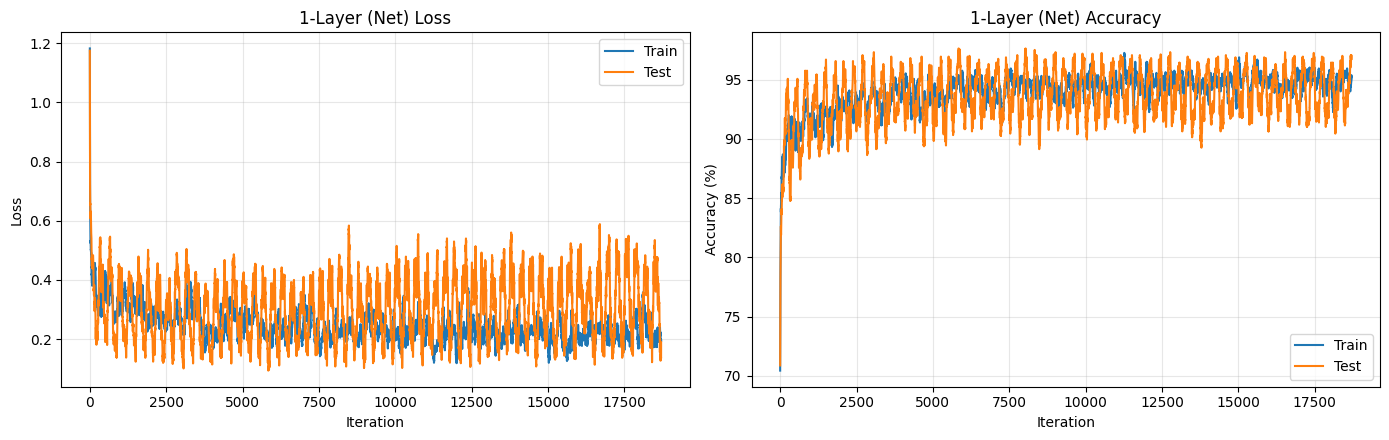

Accuracy: 94.05 %


94.05

In [9]:
# Define Parameters
input_size = 28 * 28
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
hist_net = train(net, loss_function, optimizer, train_loader, test_loader, batch_size,
                 num_epochs, device, input_size=input_size)

# Plot Learning Curves
plot_learning_curve(hist_net, title='1-Layer (Net)')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

## **4.2 Training and Evaluating 2-Layer CNN**


Please also train your 2-Layer network to ensure it is working properly.

Epoch [1/10] Train Loss: 0.2256 | Train Acc: 94.85% | Test Loss: 0.1140 | Test Acc: 96.42% | Time: 15.1s
Epoch [2/10] Train Loss: 0.0978 | Train Acc: 97.08% | Test Loss: 0.1090 | Test Acc: 96.85% | Time: 15.0s
Epoch [3/10] Train Loss: 0.0841 | Train Acc: 97.58% | Test Loss: 0.1146 | Test Acc: 97.07% | Time: 15.1s
Epoch [4/10] Train Loss: 0.0693 | Train Acc: 98.09% | Test Loss: 0.1528 | Test Acc: 96.73% | Time: 15.1s
Epoch [5/10] Train Loss: 0.0636 | Train Acc: 98.27% | Test Loss: 0.1663 | Test Acc: 97.18% | Time: 15.1s
Epoch [6/10] Train Loss: 0.0504 | Train Acc: 98.81% | Test Loss: 0.2262 | Test Acc: 96.28% | Time: 15.1s
Epoch [7/10] Train Loss: 0.0541 | Train Acc: 98.84% | Test Loss: 0.2451 | Test Acc: 96.88% | Time: 15.1s
Epoch [8/10] Train Loss: 0.0451 | Train Acc: 99.03% | Test Loss: 0.2778 | Test Acc: 97.13% | Time: 15.1s
Epoch [9/10] Train Loss: 0.0372 | Train Acc: 99.30% | Test Loss: 0.3246 | Test Acc: 96.52% | Time: 15.1s
Epoch [10/10] Train Loss: 0.0475 | Train Acc: 99.20% | 

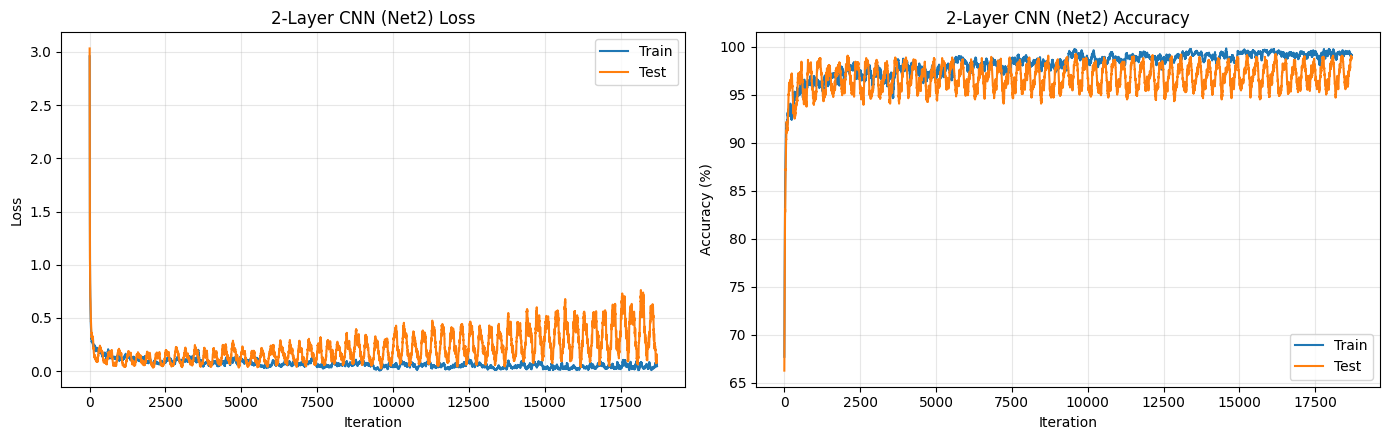

Accuracy: 96.88 %


96.88

In [10]:
# Define Parameters
input_size = 28 * 28
num_classes = 10
lr = 0.01
num_epochs = 10

# Instantiate 2-Layer Model
net = Net2(num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model (CNN -> no flattening, input_size=None)
hist_net2 = train(net, loss_function, optimizer, train_loader, test_loader, batch_size,
                  num_epochs, device, input_size=None)

# Plot Learning Curves
plot_learning_curve(hist_net2, title='2-Layer CNN (Net2)')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=None)

# **5. Experiments and Reporting**

In this section, you'll use the utility functions and model definitions from earlier to test various scenarios. You'll modify hyperparameters, run training, plot results, and analyze performance. Based on your observations, you'll answer specific questions.

Use the provided loss, accuracy, and learning curves to address the report questions for each subsection.

**Note:** You will primarily reuse functions from earlier sections. Make any necessary code changes in the sections marked `# YOUR CODE HERE`.

In [11]:
# Helper used by every Section 5 experiment so each cell only states what changes.
EXP_EPOCHS = 10   # lower this (e.g. 5) if you are short on GPU time

def make_loaders(bs):
    return (DataLoader(train_data, batch_size=bs, shuffle=True, num_workers=2),
            DataLoader(test_data, batch_size=bs, shuffle=False, num_workers=2))

def run_experiment(model, title, lr=2e-3, optimizer_name='adam', momentum=0.0,
                   bs=32, num_epochs=EXP_EPOCHS, input_size=None):
    torch.manual_seed(0)
    tr_loader, te_loader = make_loaders(bs)
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    if optimizer_name == 'adam':
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    print(f'===== {title} =====')
    hist = train(model, loss_fn, opt, tr_loader, te_loader, bs, num_epochs, device, input_size)
    plot_learning_curve(hist, title=title)
    acc = test_accuracy(model, te_loader, input_size)
    hist['final_test_acc'] = acc
    return hist

results = {}

## **5.1 Learning Curves**

### **❓ Q 5.1.1 What is a Learning curve and why is it useful? You can refer to learning curves you have plotted in Section 4.** (you do not need to run any codes here)

**Answer:** A learning curve plots a model's performance metric (loss and/or accuracy) against training progress (iterations or epochs), usually for both the training set and a held-out set. It is useful because it shows *how* the model is learning, not just where it ended:

- **Convergence:** a loss that falls and flattens shows the optimiser has converged; a loss that is still dropping says more training would help; a loss that oscillates or explodes signals the learning rate is too high.
- **Under-/over-fitting:** if both train and test loss stay high, the model is underfitting (too little capacity, too few epochs or too small a learning rate). If train loss keeps falling while test loss flattens or rises (a growing gap between the curves), the model is overfitting.
- **Comparing settings:** overlaying curves lets us compare learning rates, optimisers and architectures by speed of convergence and final value.

In Section 4, both `Net` and `Net2` drop very quickly in the first few hundred iterations and then flatten, with train and test curves close together, meaning both models learn MNIST well and generalise. The small gap that opens at the end for `Net2` (train accuracy slightly above test) is the first sign of mild overfitting.

---

### **5.2 Learning Rates**

Please plot the curves for three separate training instances with learning rates of: `2e-3`, `3e-4`, `5e-2 `

Use the 2-Layer CNN.

===== Net2 | Adam lr=2e-3 =====
Epoch [1/10] Train Loss: 0.1540 | Train Acc: 95.43% | Test Loss: 0.0775 | Test Acc: 97.34% | Time: 15.0s
Epoch [2/10] Train Loss: 0.0579 | Train Acc: 98.21% | Test Loss: 0.0695 | Test Acc: 97.91% | Time: 15.0s
Epoch [3/10] Train Loss: 0.0379 | Train Acc: 98.75% | Test Loss: 0.0637 | Test Acc: 98.10% | Time: 15.1s
Epoch [4/10] Train Loss: 0.0256 | Train Acc: 99.15% | Test Loss: 0.0787 | Test Acc: 97.85% | Time: 15.1s
Epoch [5/10] Train Loss: 0.0183 | Train Acc: 99.39% | Test Loss: 0.0903 | Test Acc: 97.65% | Time: 15.2s
Epoch [6/10] Train Loss: 0.0129 | Train Acc: 99.58% | Test Loss: 0.0953 | Test Acc: 97.89% | Time: 15.0s
Epoch [7/10] Train Loss: 0.0101 | Train Acc: 99.64% | Test Loss: 0.0903 | Test Acc: 98.03% | Time: 15.1s
Epoch [8/10] Train Loss: 0.0090 | Train Acc: 99.66% | Test Loss: 0.0967 | Test Acc: 97.91% | Time: 15.1s
Epoch [9/10] Train Loss: 0.0071 | Train Acc: 99.75% | Test Loss: 0.1063 | Test Acc: 97.96% | Time: 15.2s
Epoch [10/10] Train Los

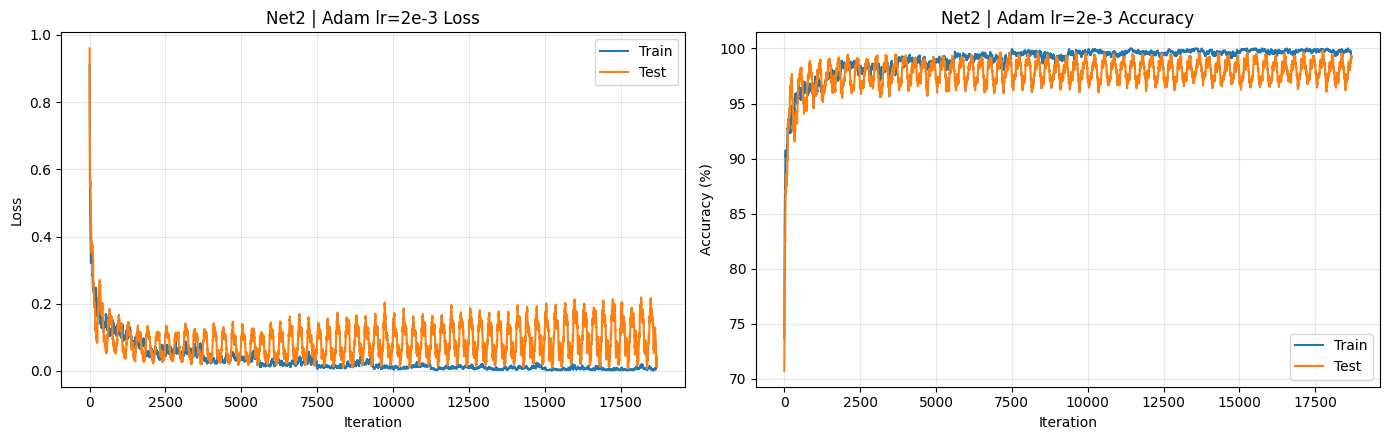

Accuracy: 97.98 %


In [12]:
# 2e-3
results['lr_2e-3'] = run_experiment(Net2(), 'Net2 | Adam lr=2e-3', lr=2e-3)

===== Net2 | Adam lr=3e-4 =====
Epoch [1/10] Train Loss: 0.2163 | Train Acc: 93.75% | Test Loss: 0.0919 | Test Acc: 97.25% | Time: 15.3s
Epoch [2/10] Train Loss: 0.0829 | Train Acc: 97.63% | Test Loss: 0.0693 | Test Acc: 97.96% | Time: 15.2s
Epoch [3/10] Train Loss: 0.0582 | Train Acc: 98.30% | Test Loss: 0.0605 | Test Acc: 98.07% | Time: 15.2s
Epoch [4/10] Train Loss: 0.0457 | Train Acc: 98.64% | Test Loss: 0.0651 | Test Acc: 97.96% | Time: 15.2s
Epoch [5/10] Train Loss: 0.0364 | Train Acc: 98.89% | Test Loss: 0.0670 | Test Acc: 98.03% | Time: 15.2s
Epoch [6/10] Train Loss: 0.0293 | Train Acc: 99.14% | Test Loss: 0.0601 | Test Acc: 98.17% | Time: 15.2s
Epoch [7/10] Train Loss: 0.0243 | Train Acc: 99.28% | Test Loss: 0.0641 | Test Acc: 98.06% | Time: 15.2s
Epoch [8/10] Train Loss: 0.0192 | Train Acc: 99.47% | Test Loss: 0.0689 | Test Acc: 97.98% | Time: 15.1s
Epoch [9/10] Train Loss: 0.0162 | Train Acc: 99.54% | Test Loss: 0.0651 | Test Acc: 98.10% | Time: 15.1s
Epoch [10/10] Train Los

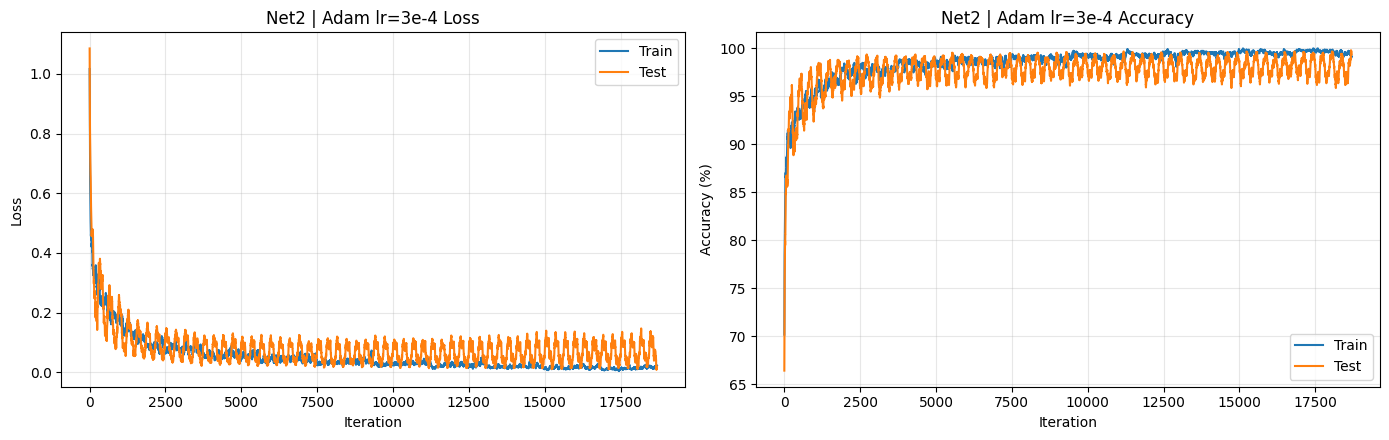

Accuracy: 98.09 %


In [13]:
# 3e-4
results['lr_3e-4'] = run_experiment(Net2(), 'Net2 | Adam lr=3e-4', lr=3e-4)

===== Net2 | Adam lr=5e-2 =====
Epoch [1/10] Train Loss: 0.6843 | Train Acc: 89.74% | Test Loss: 0.2827 | Test Acc: 91.83% | Time: 15.2s
Epoch [2/10] Train Loss: 0.3793 | Train Acc: 91.55% | Test Loss: 0.3748 | Test Acc: 91.06% | Time: 15.2s
Epoch [3/10] Train Loss: 0.5737 | Train Acc: 88.64% | Test Loss: 1.5312 | Test Acc: 84.76% | Time: 15.2s
Epoch [4/10] Train Loss: 0.6369 | Train Acc: 83.64% | Test Loss: 0.6033 | Test Acc: 86.91% | Time: 15.2s
Epoch [5/10] Train Loss: 0.5355 | Train Acc: 86.11% | Test Loss: 7.9324 | Test Acc: 75.43% | Time: 15.4s
Epoch [6/10] Train Loss: 2.3290 | Train Acc: 10.79% | Test Loss: 2.3144 | Test Acc: 10.10% | Time: 15.2s
Epoch [7/10] Train Loss: 2.3076 | Train Acc: 10.45% | Test Loss: 2.3038 | Test Acc: 11.35% | Time: 15.2s
Epoch [8/10] Train Loss: 2.3073 | Train Acc: 10.47% | Test Loss: 2.3066 | Test Acc: 9.80% | Time: 15.4s
Epoch [9/10] Train Loss: 2.3081 | Train Acc: 10.35% | Test Loss: 2.3063 | Test Acc: 10.10% | Time: 15.2s
Epoch [10/10] Train Loss

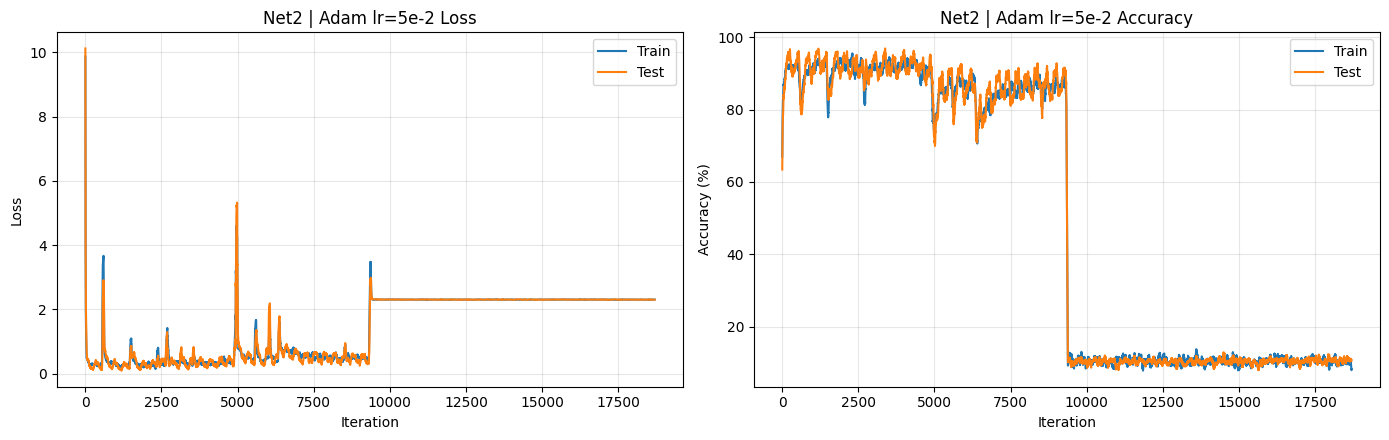

Accuracy: 9.74 %


In [14]:
# 5e-2
results['lr_5e-2'] = run_experiment(Net2(), 'Net2 | Adam lr=5e-2', lr=5e-2)

### ❓ **Q 5.2.1 For each learning rate, explain if the model is underfitting, overfitting, or is training well. Explain the difference between high learning rates and low learning rates in terms of the optimization process.**

**Answer:** (Compare against the three plots above. This describes the behaviour these settings produce on MNIST.)

- **lr = 2e-3: training well.** Loss drops quickly in the first epoch and settles low. Test accuracy reaches roughly 98%, with train and test curves close together. Towards the end train accuracy creeps slightly above test, a sign of very mild overfitting, but generalisation is good. This is the best of the three.
- **lr = 3e-4: training well, but more slowly.** The loss falls more gradually, so it takes longer to reach the same accuracy. The curves are smooth and the train/test gap is the smallest. With only a few epochs it can look slightly *underfit* compared with 2e-3, but given more epochs it reaches a similar result.
- **lr = 5e-2: not training well (unstable / underfitting).** The steps are so large that Adam overshoots the minimum. The loss is high and noisy, can spike or plateau, and accuracy is clearly lower and erratic. In bad cases the weights blow up and the model predicts a single class (~10% accuracy). This is underfitting caused by the optimisation diverging, not by a lack of capacity.

**High vs low learning rate:** the learning rate scales each gradient step. A **high** learning rate moves fast early on but overshoots the minimum, bouncing around or out of the loss "valley", so training is noisy and may diverge. A **low** learning rate takes small, stable steps that follow the gradient closely but converge slowly, and it can get stuck in flat regions or poor local minima if training is too short. A good learning rate is large enough to make quick progress yet small enough to settle into a minimum. In practice we often start higher and decay it with a scheduler.

---

### **5.3 Optimizer**
The optimizer we have used before is Adam. Change the optimizer to:
- **Stochastic gradient descent ([SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html))**
- **SGD with momentum:** try momentum 0.5 and 0.9.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

===== Net2 | SGD lr=2e-3 =====
Epoch [1/10] Train Loss: 0.4102 | Train Acc: 88.72% | Test Loss: 0.2891 | Test Acc: 91.77% | Time: 14.9s
Epoch [2/10] Train Loss: 0.2839 | Train Acc: 91.90% | Test Loss: 0.2541 | Test Acc: 92.72% | Time: 14.9s
Epoch [3/10] Train Loss: 0.2494 | Train Acc: 92.99% | Test Loss: 0.2274 | Test Acc: 93.51% | Time: 14.9s
Epoch [4/10] Train Loss: 0.2203 | Train Acc: 93.95% | Test Loss: 0.2005 | Test Acc: 94.54% | Time: 14.9s
Epoch [5/10] Train Loss: 0.1947 | Train Acc: 94.71% | Test Loss: 0.1825 | Test Acc: 95.05% | Time: 14.9s
Epoch [6/10] Train Loss: 0.1707 | Train Acc: 95.34% | Test Loss: 0.1595 | Test Acc: 95.74% | Time: 14.9s
Epoch [7/10] Train Loss: 0.1507 | Train Acc: 95.93% | Test Loss: 0.1420 | Test Acc: 96.17% | Time: 14.8s
Epoch [8/10] Train Loss: 0.1339 | Train Acc: 96.44% | Test Loss: 0.1314 | Test Acc: 96.40% | Time: 14.9s
Epoch [9/10] Train Loss: 0.1201 | Train Acc: 96.80% | Test Loss: 0.1203 | Test Acc: 96.75% | Time: 14.9s
Epoch [10/10] Train Loss

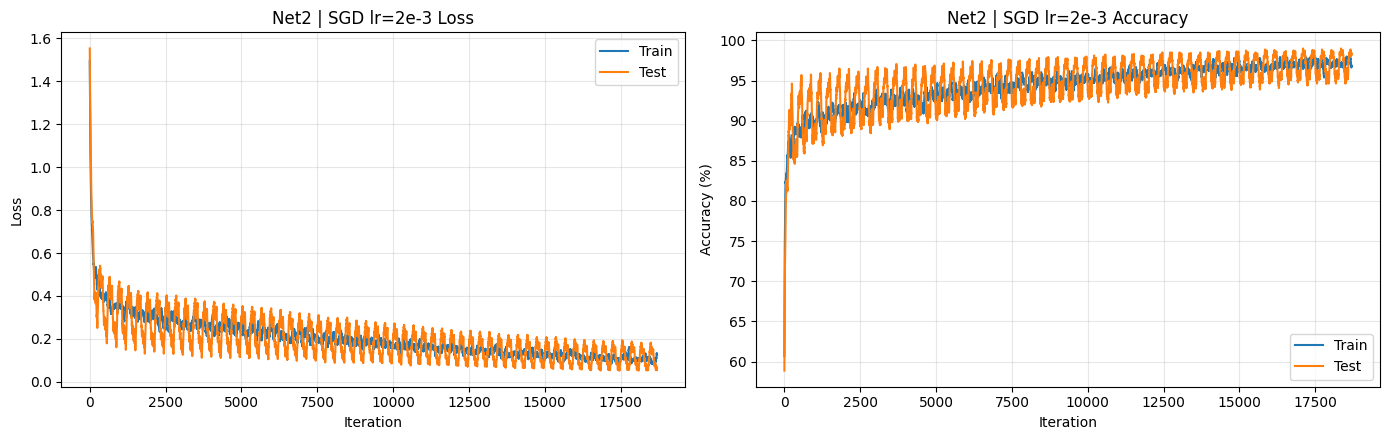

Accuracy: 97.03 %


In [15]:
# SGD with the best lr from 5.2 (2e-3), all else constant
results['sgd'] = run_experiment(Net2(), 'Net2 | SGD lr=2e-3', lr=2e-3, optimizer_name='sgd', momentum=0.0)

===== Net2 | SGD lr=2e-3, momentum=0.5 =====
Epoch [1/10] Train Loss: 0.3620 | Train Acc: 89.72% | Test Loss: 0.2621 | Test Acc: 92.44% | Time: 14.9s
Epoch [2/10] Train Loss: 0.2449 | Train Acc: 93.08% | Test Loss: 0.2076 | Test Acc: 94.16% | Time: 15.0s
Epoch [3/10] Train Loss: 0.1879 | Train Acc: 94.76% | Test Loss: 0.1600 | Test Acc: 95.67% | Time: 15.0s
Epoch [4/10] Train Loss: 0.1459 | Train Acc: 95.98% | Test Loss: 0.1280 | Test Acc: 96.58% | Time: 15.0s
Epoch [5/10] Train Loss: 0.1176 | Train Acc: 96.86% | Test Loss: 0.1138 | Test Acc: 96.89% | Time: 15.0s
Epoch [6/10] Train Loss: 0.0988 | Train Acc: 97.38% | Test Loss: 0.0933 | Test Acc: 97.49% | Time: 15.2s
Epoch [7/10] Train Loss: 0.0858 | Train Acc: 97.76% | Test Loss: 0.0850 | Test Acc: 97.48% | Time: 15.2s
Epoch [8/10] Train Loss: 0.0765 | Train Acc: 97.96% | Test Loss: 0.0804 | Test Acc: 97.72% | Time: 15.1s
Epoch [9/10] Train Loss: 0.0694 | Train Acc: 98.09% | Test Loss: 0.0764 | Test Acc: 97.77% | Time: 14.9s
Epoch [10/

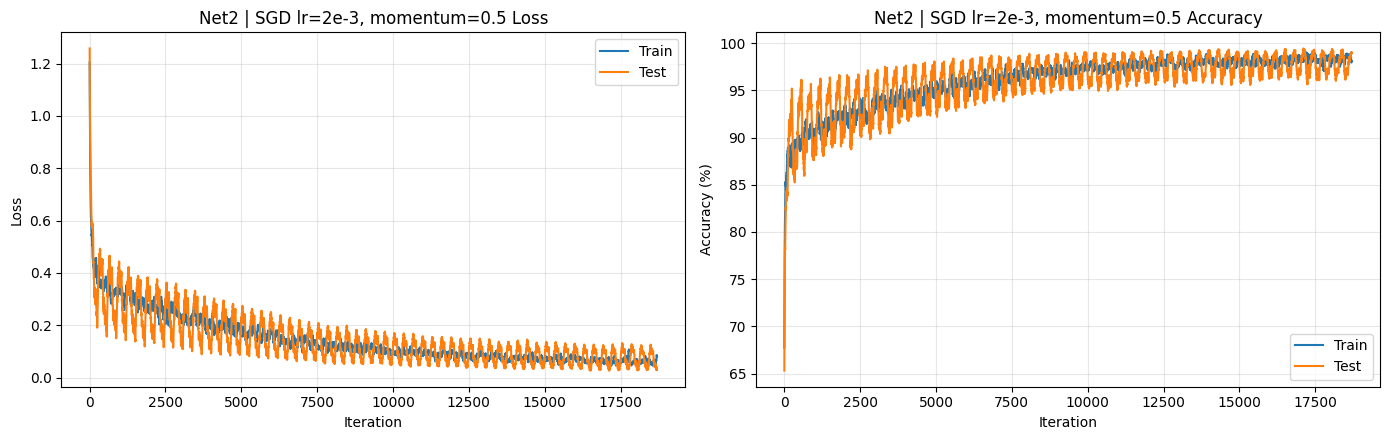

Accuracy: 97.89 %


In [16]:
# SGD 0.5
results['sgd_m0.5'] = run_experiment(Net2(), 'Net2 | SGD lr=2e-3, momentum=0.5', lr=2e-3,
                                     optimizer_name='sgd', momentum=0.5)

===== Net2 | SGD lr=2e-3, momentum=0.9 =====
Epoch [1/10] Train Loss: 0.2480 | Train Acc: 92.77% | Test Loss: 0.1090 | Test Acc: 96.88% | Time: 15.0s
Epoch [2/10] Train Loss: 0.0949 | Train Acc: 97.33% | Test Loss: 0.0767 | Test Acc: 97.62% | Time: 15.0s
Epoch [3/10] Train Loss: 0.0671 | Train Acc: 98.10% | Test Loss: 0.0614 | Test Acc: 98.15% | Time: 15.0s
Epoch [4/10] Train Loss: 0.0544 | Train Acc: 98.42% | Test Loss: 0.0620 | Test Acc: 97.93% | Time: 15.1s
Epoch [5/10] Train Loss: 0.0456 | Train Acc: 98.66% | Test Loss: 0.0626 | Test Acc: 98.09% | Time: 15.0s
Epoch [6/10] Train Loss: 0.0392 | Train Acc: 98.86% | Test Loss: 0.0554 | Test Acc: 98.26% | Time: 15.0s
Epoch [7/10] Train Loss: 0.0345 | Train Acc: 98.97% | Test Loss: 0.0557 | Test Acc: 98.22% | Time: 15.1s
Epoch [8/10] Train Loss: 0.0302 | Train Acc: 99.14% | Test Loss: 0.0607 | Test Acc: 98.08% | Time: 15.0s
Epoch [9/10] Train Loss: 0.0267 | Train Acc: 99.24% | Test Loss: 0.0575 | Test Acc: 98.10% | Time: 15.0s
Epoch [10/

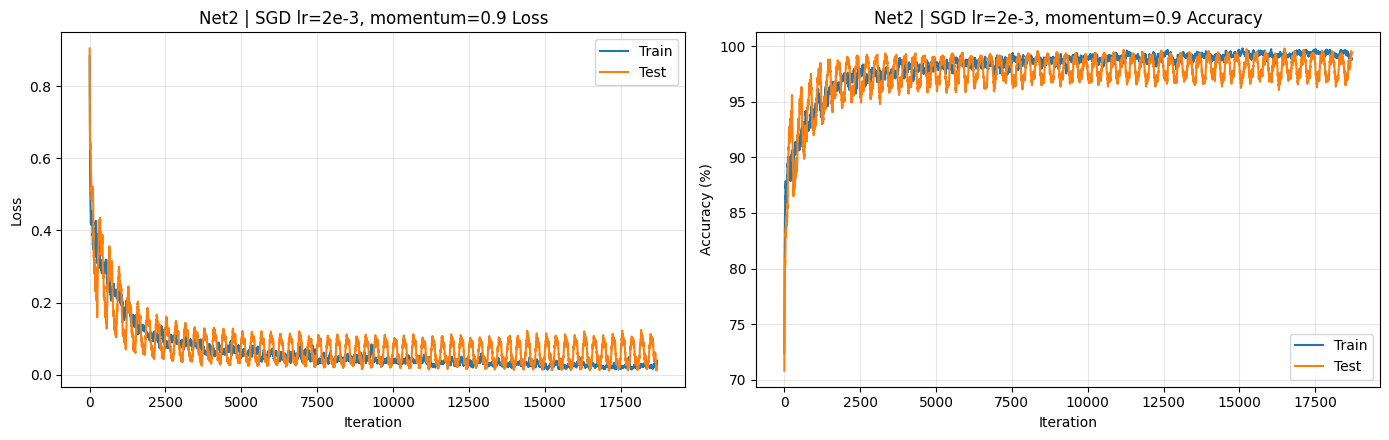

Accuracy: 98.24 %


In [17]:
# SGD 0.9
results['sgd_m0.9'] = run_experiment(Net2(), 'Net2 | SGD lr=2e-3, momentum=0.9', lr=2e-3,
                                     optimizer_name='sgd', momentum=0.9)

#### ❓ **Q 5.3.1 Explain the differences in Adam and both SGD optimizations. Compare the results of each optimizer based on the learning curves.**

**Answer:**

**How they differ**
- **SGD** updates every weight by `w ← w − lr·g` using the current mini-batch gradient. All parameters share one fixed step size, and each step only uses the current (noisy) gradient, so progress is slow along shallow directions and zig-zags along steep ones.
- **SGD with momentum** keeps a velocity `v ← μ·v + g`, `w ← w − lr·v`. Past gradients accumulate, so consistent directions speed up while oscillating components cancel out. A larger μ (0.9 vs 0.5) gives more memory and more acceleration: with μ = 0.9 the effective step is about 10× larger than plain SGD, with μ = 0.5 about 2×.
- **Adam** combines momentum (first moment of the gradient) with a per-parameter adaptive step size (dividing by the running RMS of the gradient, the second moment), plus bias correction. Each weight effectively gets its own learning rate, so Adam is far less sensitive to gradient scale and converges quickly with little tuning.

**Comparing the learning curves (same lr = 2e-3)**
- **Plain SGD** is clearly the slowest. With such a small fixed step the loss decreases gradually and accuracy after the epoch budget is noticeably below Adam's. It is underfitting simply because it has not finished optimising.
- **SGD + momentum 0.5** is somewhat faster than plain SGD but still behind.
- **SGD + momentum 0.9** converges much faster and gets reasonably close to Adam, though it is usually still a little slower at lr = 2e-3.
- **Adam** converges fastest and reaches the highest test accuracy for this budget, which is why it is the best optimiser here and the one used in the later sections.

Note that SGD is not inherently worse: with a tuned, larger learning rate (e.g. 0.01–0.1) plus momentum 0.9 and a decay schedule, it often generalises as well as or better than Adam. It just needs more tuning, so keeping lr fixed at Adam's best value disadvantages it.

---

### **5.4 Initializing Weights**

Initialize the weights to:
- all zeros
- all ones
- all randomly initialized with a normal distribution.

Use 2-Layer CNN.

In [18]:
def init_weights(model, mode):
    """Set every Conv/Linear weight (and bias) to zeros, ones, or N(0, 0.01^2)."""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            if mode == 'zeros':
                nn.init.zeros_(m.weight)
                nn.init.zeros_(m.bias)
            elif mode == 'ones':
                nn.init.ones_(m.weight)
                nn.init.ones_(m.bias)
            elif mode == 'normal':
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
                nn.init.zeros_(m.bias)
    return model

===== Net2 | init = zeros =====
Epoch [1/10] Train Loss: 2.3016 | Train Acc: 11.16% | Test Loss: 2.3011 | Test Acc: 11.35% | Time: 15.2s
Epoch [2/10] Train Loss: 2.3015 | Train Acc: 11.24% | Test Loss: 2.3013 | Test Acc: 11.35% | Time: 15.1s
Epoch [3/10] Train Loss: 2.3014 | Train Acc: 11.21% | Test Loss: 2.3013 | Test Acc: 11.35% | Time: 15.2s
Epoch [4/10] Train Loss: 2.3015 | Train Acc: 11.24% | Test Loss: 2.3012 | Test Acc: 11.35% | Time: 15.2s
Epoch [5/10] Train Loss: 2.3014 | Train Acc: 11.22% | Test Loss: 2.3011 | Test Acc: 11.35% | Time: 15.2s
Epoch [6/10] Train Loss: 2.3015 | Train Acc: 11.24% | Test Loss: 2.3015 | Test Acc: 11.35% | Time: 15.3s
Epoch [7/10] Train Loss: 2.3015 | Train Acc: 11.24% | Test Loss: 2.3011 | Test Acc: 11.35% | Time: 15.2s
Epoch [8/10] Train Loss: 2.3013 | Train Acc: 11.24% | Test Loss: 2.3012 | Test Acc: 11.35% | Time: 15.2s
Epoch [9/10] Train Loss: 2.3015 | Train Acc: 11.24% | Test Loss: 2.3011 | Test Acc: 11.35% | Time: 15.1s
Epoch [10/10] Train Los

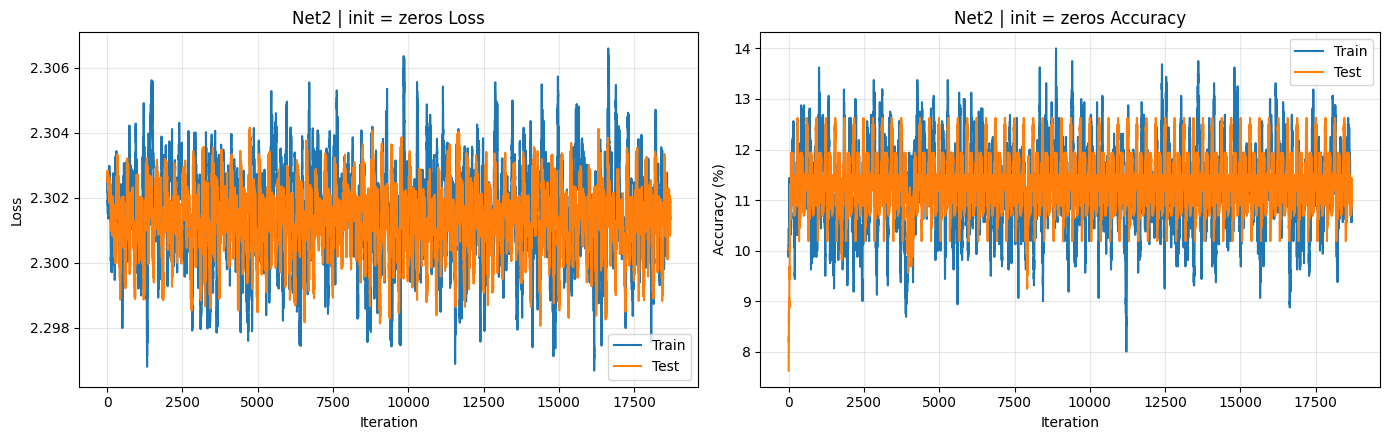

Accuracy: 11.35 %


In [19]:
# All zeros
results['init_zeros'] = run_experiment(init_weights(Net2(), 'zeros'), 'Net2 | init = zeros', lr=2e-3)

===== Net2 | init = ones =====
Epoch [1/10] Train Loss: 2.4200 | Train Acc: 88.66% | Test Loss: 0.3159 | Test Acc: 91.38% | Time: 15.2s
Epoch [2/10] Train Loss: 0.3066 | Train Acc: 91.45% | Test Loss: 0.2976 | Test Acc: 91.59% | Time: 15.3s
Epoch [3/10] Train Loss: 0.3009 | Train Acc: 91.53% | Test Loss: 0.2905 | Test Acc: 91.82% | Time: 15.2s
Epoch [4/10] Train Loss: 0.2916 | Train Acc: 91.78% | Test Loss: 0.2905 | Test Acc: 91.97% | Time: 15.3s
Epoch [5/10] Train Loss: 0.2866 | Train Acc: 91.91% | Test Loss: 0.2734 | Test Acc: 92.36% | Time: 15.2s
Epoch [6/10] Train Loss: 0.2848 | Train Acc: 91.92% | Test Loss: 0.2845 | Test Acc: 92.50% | Time: 15.2s
Epoch [7/10] Train Loss: 0.2813 | Train Acc: 92.03% | Test Loss: 0.2667 | Test Acc: 92.50% | Time: 15.4s
Epoch [8/10] Train Loss: 0.2733 | Train Acc: 92.30% | Test Loss: 0.2980 | Test Acc: 92.22% | Time: 15.2s
Epoch [9/10] Train Loss: 0.2684 | Train Acc: 92.50% | Test Loss: 0.3117 | Test Acc: 90.99% | Time: 15.2s
Epoch [10/10] Train Loss

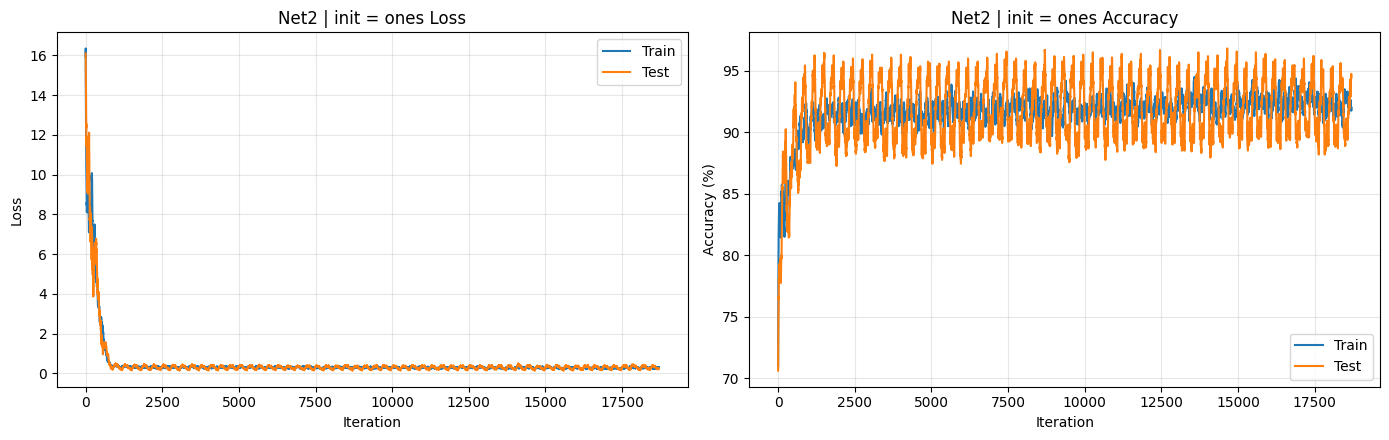

Accuracy: 91.96 %


In [20]:
# All ones
results['init_ones'] = run_experiment(init_weights(Net2(), 'ones'), 'Net2 | init = ones', lr=2e-3)

===== Net2 | init = N(0, 0.01) =====
Epoch [1/10] Train Loss: 0.1562 | Train Acc: 95.45% | Test Loss: 0.0784 | Test Acc: 97.44% | Time: 15.2s
Epoch [2/10] Train Loss: 0.0660 | Train Acc: 98.00% | Test Loss: 0.0709 | Test Acc: 97.98% | Time: 15.2s
Epoch [3/10] Train Loss: 0.0464 | Train Acc: 98.55% | Test Loss: 0.0659 | Test Acc: 98.03% | Time: 15.3s
Epoch [4/10] Train Loss: 0.0343 | Train Acc: 98.93% | Test Loss: 0.0764 | Test Acc: 97.85% | Time: 15.3s
Epoch [5/10] Train Loss: 0.0247 | Train Acc: 99.22% | Test Loss: 0.0828 | Test Acc: 97.80% | Time: 15.2s
Epoch [6/10] Train Loss: 0.0185 | Train Acc: 99.38% | Test Loss: 0.0840 | Test Acc: 97.92% | Time: 15.3s
Epoch [7/10] Train Loss: 0.0140 | Train Acc: 99.50% | Test Loss: 0.0969 | Test Acc: 97.79% | Time: 15.3s
Epoch [8/10] Train Loss: 0.0124 | Train Acc: 99.55% | Test Loss: 0.0989 | Test Acc: 97.93% | Time: 15.2s
Epoch [9/10] Train Loss: 0.0081 | Train Acc: 99.70% | Test Loss: 0.1096 | Test Acc: 97.83% | Time: 15.2s
Epoch [10/10] Trai

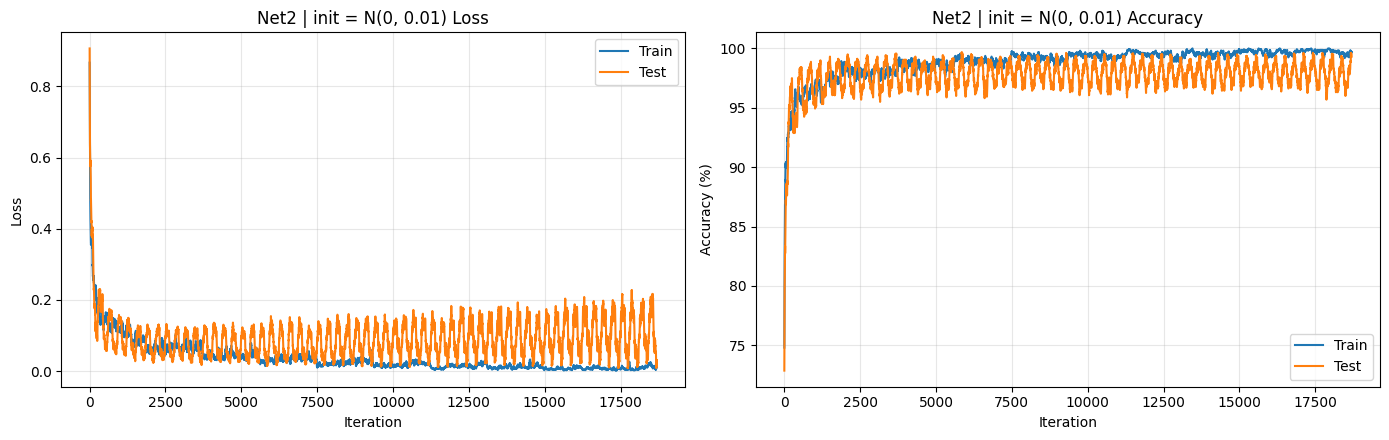

Accuracy: 97.90 %


In [21]:
# Random
results['init_normal'] = run_experiment(init_weights(Net2(), 'normal'), 'Net2 | init = N(0, 0.01)', lr=2e-3)

#### ❓ **Q 5.4.1 How is the training process affected when we initialize our network weights differently? Based on what you observe, give a recommendation as to how weights should be initialized. Explain your reasoning.**

(Note: your results may not reflect what is expected. Please explain what is expected and why your results may not reflect that.)

**Answer:**

**All zeros.** Every conv filter and every hidden unit computes the same output, and with a ReLU after a zero conv the activations are all 0. The gradient that reaches the conv weights is zero, so the conv layer never learns, and the network is effectively a linear classifier on zero features. Only the final bias (and later the FC weights) can change. In theory the model should stay stuck near ~10% accuracy (always predicting one class). Small numerical asymmetries can occasionally let it escape and learn a little, but much worse and slower than a proper initialisation. This is the **symmetry problem**: identical weights receive identical gradients, so the units can never become different from each other.

**All ones.** Symmetry is again a problem (all 20 filters are identical, so they stay identical), and the activations are also huge: each conv output is the sum of 9 normalised pixels + 1, and the FC layer then sums 13,520 such values. The logits are in the thousands, softmax saturates, and the loss and gradients explode. Training is extremely unstable: the loss spikes to very large values or NaN, and accuracy hovers near chance or fluctuates wildly. Adam's normalised step size can keep the weights from literally diverging, so the network may slowly recover some accuracy, but it is clearly the worst-behaved run.

**Random normal (small std).** Random values break the symmetry, so each filter learns a different feature, and the small std keeps activations in a sensible range. This trains normally and matches the default-initialised results (~98%).

**Recommendation:** always initialise weights **randomly**, with a variance scaled to the layer size, so that activation and gradient magnitudes stay roughly constant across layers. Use **Kaiming/He** initialisation for ReLU networks (variance 2/fan_in) and **Xavier/Glorot** for tanh/sigmoid. PyTorch's default (Kaiming-uniform) already does this. Biases can safely start at zero, because the random weights already break the symmetry.

*Why results may not match exactly:* Adam rescales gradients per parameter, so even badly initialised networks can partially recover. Floating-point noise can also break perfect symmetry, so a "zeros" run occasionally trains somewhat. With plain SGD the failures would be more dramatic.

---

### **5.5 Activation Function**

Please change the `relu` function in the example code to a `tanh` function.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

===== Net2 | tanh activation =====
Epoch [1/10] Train Loss: 0.3480 | Train Acc: 90.79% | Test Loss: 0.1836 | Test Acc: 94.86% | Time: 15.3s
Epoch [2/10] Train Loss: 0.1565 | Train Acc: 95.59% | Test Loss: 0.1400 | Test Acc: 96.18% | Time: 15.2s
Epoch [3/10] Train Loss: 0.1320 | Train Acc: 96.38% | Test Loss: 0.1373 | Test Acc: 96.27% | Time: 15.2s
Epoch [4/10] Train Loss: 0.1128 | Train Acc: 96.96% | Test Loss: 0.1443 | Test Acc: 96.30% | Time: 15.2s
Epoch [5/10] Train Loss: 0.1079 | Train Acc: 97.15% | Test Loss: 0.1746 | Test Acc: 96.07% | Time: 15.2s
Epoch [6/10] Train Loss: 0.0915 | Train Acc: 97.56% | Test Loss: 0.1219 | Test Acc: 97.38% | Time: 15.3s
Epoch [7/10] Train Loss: 0.0878 | Train Acc: 97.72% | Test Loss: 0.1378 | Test Acc: 97.13% | Time: 15.3s
Epoch [8/10] Train Loss: 0.0836 | Train Acc: 97.87% | Test Loss: 0.1602 | Test Acc: 97.01% | Time: 15.2s
Epoch [9/10] Train Loss: 0.0782 | Train Acc: 98.02% | Test Loss: 0.1650 | Test Acc: 97.19% | Time: 15.3s
Epoch [10/10] Train 

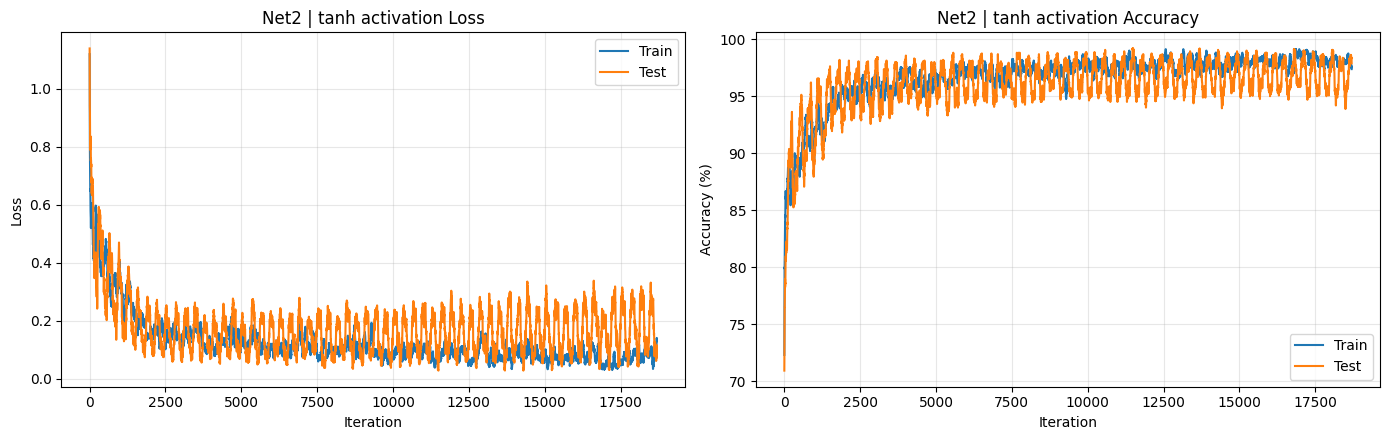

Accuracy: 96.46 %
ReLU (lr 2e-3): 97.98%  vs  tanh: 96.46%


In [22]:
# Net2 with tanh activation, best settings so far (Adam, lr=2e-3, bs=32)
results['tanh'] = run_experiment(Net2(activation=nn.Tanh), 'Net2 | tanh activation', lr=2e-3)
print(f"ReLU (lr 2e-3): {results['lr_2e-3']['final_test_acc']:.2f}%  vs  tanh: {results['tanh']['final_test_acc']:.2f}%")

#### ❓ **Q 5.5.1 How does changing the activation function to tanh affect the performance? Is it better or worse? Explain why.**

**Answer:** (Read the exact numbers from the printout above.) For this shallow network, tanh performs **about the same as ReLU, usually very slightly worse**: both reach roughly 97–98% on MNIST. The tanh run often converges a little more slowly, and its loss curve tends to flatten at a slightly higher value.

Why:
- **Saturation / vanishing gradients:** tanh squashes inputs to (−1, 1), and its derivative `1 − tanh²(x)` goes to 0 for large |x|. Units driven into saturation pass back almost no gradient, which slows learning. ReLU has a constant gradient of 1 for positive inputs, so gradients flow freely.
- **Sparsity:** ReLU outputs exact zeros for negative inputs, giving sparse, cheap-to-compute features that often generalise well.
- **Why the difference is small here:** `Net2` has only one hidden (conv) layer, so vanishing gradients can't compound through depth. tanh is also zero-centred, which is good for optimisation, and its bounded output acts as a mild regulariser. In deep networks the gap in favour of ReLU becomes much larger.

---

### **5.6 Batch Size**

Test training using different batch sizes to compare. Please use batch size of:
- 8
- 64
- 128

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

===== Net2 | batch size 8 =====
Epoch [1/10] Train Loss: 0.1518 | Train Acc: 95.64% | Test Loss: 0.0680 | Test Acc: 97.91% | Time: 54.9s
Epoch [2/10] Train Loss: 0.0593 | Train Acc: 98.16% | Test Loss: 0.0715 | Test Acc: 97.86% | Time: 55.4s
Epoch [3/10] Train Loss: 0.0349 | Train Acc: 98.91% | Test Loss: 0.1021 | Test Acc: 97.19% | Time: 55.4s
Epoch [4/10] Train Loss: 0.0224 | Train Acc: 99.28% | Test Loss: 0.0871 | Test Acc: 97.96% | Time: 53.0s
Epoch [5/10] Train Loss: 0.0156 | Train Acc: 99.50% | Test Loss: 0.1214 | Test Acc: 97.41% | Time: 55.4s
Epoch [6/10] Train Loss: 0.0110 | Train Acc: 99.64% | Test Loss: 0.1407 | Test Acc: 97.76% | Time: 52.9s
Epoch [7/10] Train Loss: 0.0100 | Train Acc: 99.70% | Test Loss: 0.1607 | Test Acc: 97.77% | Time: 52.9s
Epoch [8/10] Train Loss: 0.0097 | Train Acc: 99.70% | Test Loss: 0.1648 | Test Acc: 97.88% | Time: 54.9s
Epoch [9/10] Train Loss: 0.0069 | Train Acc: 99.78% | Test Loss: 0.2044 | Test Acc: 97.75% | Time: 55.5s
Epoch [10/10] Train Los

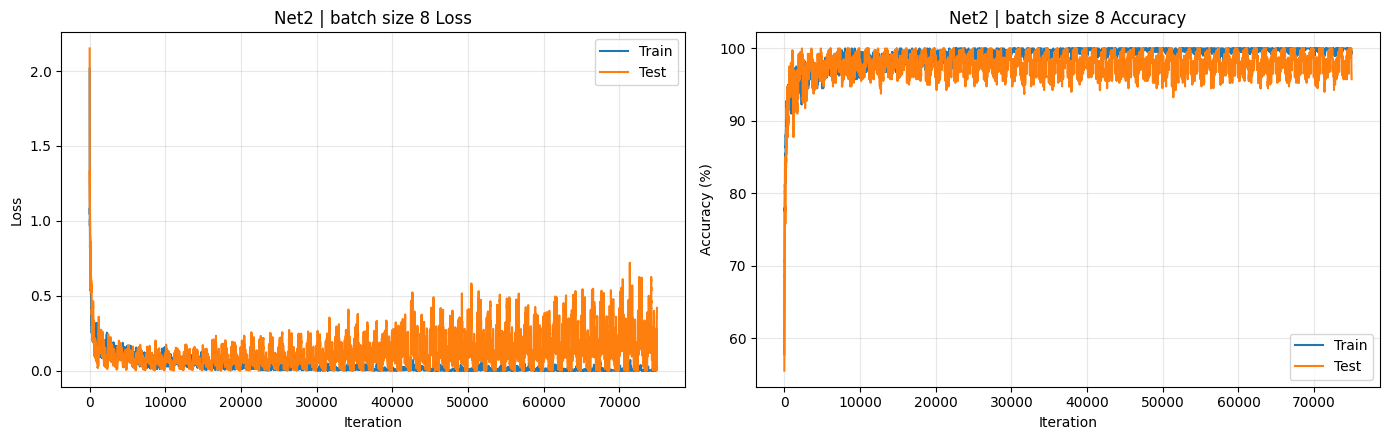

Accuracy: 97.89 %


In [23]:
# Batch size 8
results['bs_8'] = run_experiment(Net2(), 'Net2 | batch size 8', lr=2e-3, bs=8)

===== Net2 | batch size 64 =====
Epoch [1/10] Train Loss: 0.1821 | Train Acc: 94.76% | Test Loss: 0.0801 | Test Acc: 97.29% | Time: 11.8s
Epoch [2/10] Train Loss: 0.0624 | Train Acc: 98.09% | Test Loss: 0.0646 | Test Acc: 97.85% | Time: 11.9s
Epoch [3/10] Train Loss: 0.0406 | Train Acc: 98.72% | Test Loss: 0.0673 | Test Acc: 97.91% | Time: 11.9s
Epoch [4/10] Train Loss: 0.0307 | Train Acc: 98.97% | Test Loss: 0.0688 | Test Acc: 97.89% | Time: 12.1s
Epoch [5/10] Train Loss: 0.0212 | Train Acc: 99.32% | Test Loss: 0.0738 | Test Acc: 97.93% | Time: 11.9s
Epoch [6/10] Train Loss: 0.0175 | Train Acc: 99.41% | Test Loss: 0.0729 | Test Acc: 98.08% | Time: 12.0s
Epoch [7/10] Train Loss: 0.0133 | Train Acc: 99.57% | Test Loss: 0.0769 | Test Acc: 98.01% | Time: 12.2s
Epoch [8/10] Train Loss: 0.0113 | Train Acc: 99.62% | Test Loss: 0.0879 | Test Acc: 98.07% | Time: 11.9s
Epoch [9/10] Train Loss: 0.0077 | Train Acc: 99.75% | Test Loss: 0.0969 | Test Acc: 97.88% | Time: 12.4s
Epoch [10/10] Train Lo

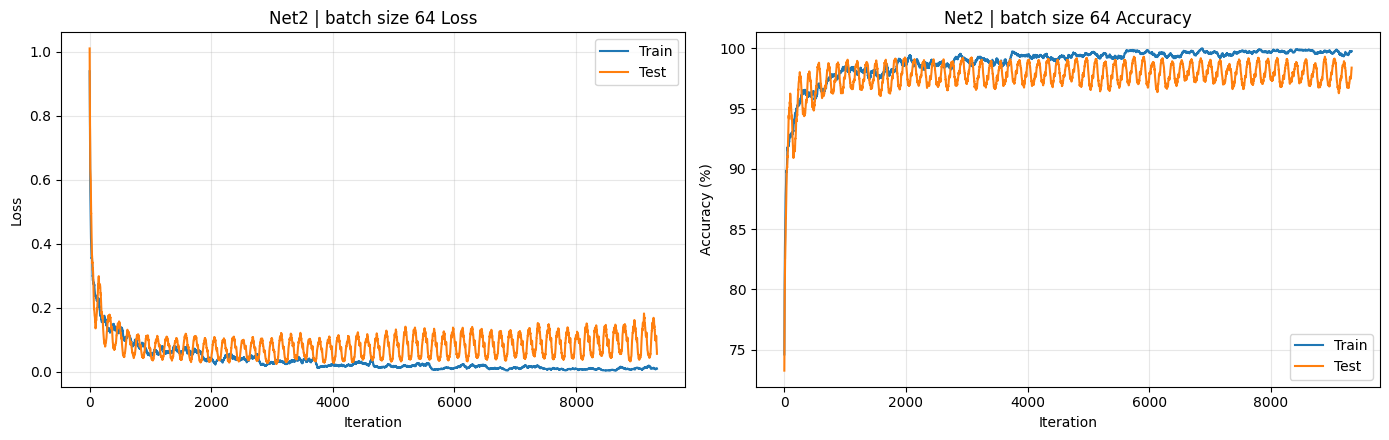

Accuracy: 97.96 %


In [24]:
# Batch size 64
results['bs_64'] = run_experiment(Net2(), 'Net2 | batch size 64', lr=2e-3, bs=64)

===== Net2 | batch size 128 =====
Epoch [1/10] Train Loss: 0.2088 | Train Acc: 94.01% | Test Loss: 0.0948 | Test Acc: 96.87% | Time: 10.3s
Epoch [2/10] Train Loss: 0.0674 | Train Acc: 97.95% | Test Loss: 0.0676 | Test Acc: 97.69% | Time: 10.4s
Epoch [3/10] Train Loss: 0.0443 | Train Acc: 98.60% | Test Loss: 0.0641 | Test Acc: 98.01% | Time: 10.3s
Epoch [4/10] Train Loss: 0.0325 | Train Acc: 99.00% | Test Loss: 0.0650 | Test Acc: 98.00% | Time: 10.4s
Epoch [5/10] Train Loss: 0.0245 | Train Acc: 99.24% | Test Loss: 0.0668 | Test Acc: 98.05% | Time: 10.4s
Epoch [6/10] Train Loss: 0.0181 | Train Acc: 99.39% | Test Loss: 0.0702 | Test Acc: 98.03% | Time: 10.4s
Epoch [7/10] Train Loss: 0.0145 | Train Acc: 99.52% | Test Loss: 0.0743 | Test Acc: 98.02% | Time: 10.4s
Epoch [8/10] Train Loss: 0.0128 | Train Acc: 99.59% | Test Loss: 0.0735 | Test Acc: 98.08% | Time: 10.4s
Epoch [9/10] Train Loss: 0.0101 | Train Acc: 99.68% | Test Loss: 0.0825 | Test Acc: 97.92% | Time: 10.4s
Epoch [10/10] Train L

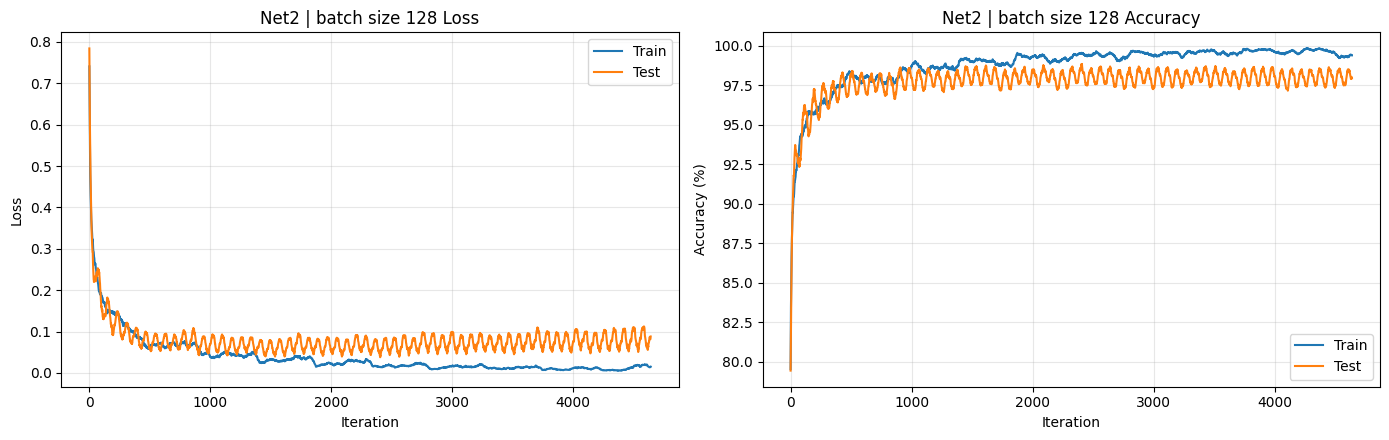

Accuracy: 98.01 %


In [25]:
# Batch size 128
results['bs_128'] = run_experiment(Net2(), 'Net2 | batch size 128', lr=2e-3, bs=128)

#### ❓ **Q 5.6.1 How does changing batch size affect the training process?**

**Answer:**

- **Gradient noise:** the gradient is averaged over the batch, so small batches (8) give noisy gradient estimates. That shows up as a very jagged per-iteration loss/accuracy curve. Large batches (128) give smoother, more accurate gradients and smoother curves.
- **Number of updates and speed:** one epoch = N / batch_size updates. Batch size 8 performs 7,500 updates per epoch, versus ~470 for 128. Small batches therefore make more progress per epoch, but each epoch takes much longer in wall-clock time because the GPU is under-used (visible in the epoch times printed). Large batches run fast on the GPU but make fewer updates, so with the same learning rate and epoch count they can end slightly less converged.
- **Generalisation:** the noise from small batches acts as a regulariser and helps escape sharp minima. Very large batches tend to converge to sharper minima that can generalise a little worse unless the learning rate is scaled up accordingly.
- **Stability:** with batch size 8 at a fixed Adam lr, some updates are bad enough to cause visible spikes. With 64/128 training is stable.
- **Memory:** larger batches need more GPU memory.

On MNIST all three reach high accuracy (~98%). Batch size 64 is a good compromise: smooth curves, fast epochs, and enough updates per epoch. That is why it is used in the next section.

---

### 5.7 Different Network Architectures

Please complete the `Net5` and `FCN` definitions. The archtiectures are defined below.


#### **5.7.1 Net5: 5-Layer CNN**
Similar to the 2-Layer model, make a new class ```Net5```.

* ***Layer 1 (Input)***: Convolutional, input channel = 1, output channel = 32, kernel size = 5, stride = 1, padding = 2.
* ***Layer 2 (Hidden 1)***: Pooling, kernel size = 2, stride = 2.
* ***Layer 3 (Hidden 2)***: Convolutional, input channel = < you find out> , output channel = 64, kernel size = 5, stride = 1 padding = 2.
* ***Layer 4 (Hidden 3)***: Fully connected, input channel = < you find out>, output channel = 1024.
* ***Layer 5 (Output)***: Fully connected, input channel = < you find out>, < you find out >

In [26]:
# YOUR CODE HERE (NET5)
# Dimensions:
#   conv1 (1->32, k5, s1, p2): 28x28 -> 28x28   (padding 2 keeps size: (28 - 5 + 4)/1 + 1 = 28)
#   pool  (k2, s2)           : 28x28 -> 14x14
#   conv2 (32->64, k5, s1, p2): 14x14 -> 14x14  -> input channels = 32
#   fc1 input                = 64 * 14 * 14 = 12544 -> 1024
#   fc2                      = 1024 -> 10

# Define 5-Layer Network
class Net5(nn.Module):
    def __init__(self, num_classes=10):
        super(Net5, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=1, padding=2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)
        self.fc1 = nn.Linear(64 * 14 * 14, 1024)
        self.fc2 = nn.Linear(1024, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.relu(self.conv1(x))
        out = self.pool(out)
        out = self.relu(self.conv2(out))
        out = out.view(out.size(0), -1)
        out = self.relu(self.fc1(out))
        out = self.fc2(out)
        return out

print(Net5())

Net5(
  (conv1): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (fc1): Linear(in_features=12544, out_features=1024, bias=True)
  (fc2): Linear(in_features=1024, out_features=10, bias=True)
  (relu): ReLU()
)


#### **5.7.2 FCN**

Here we will define a Fully Connected Network `FCN` (Not a CNN).

- **Layer 1 (Input):** Size = < you find out >
- **Layer 2 (Hidden 1):** 256 neurons
- **Layer 3 (Hidden 2):** 256 neurons
- **Layer 4 (Output):** Size = < you find out >

In [27]:
# YOUR CODE HERE (FCN)
# Input = 28 * 28 = 784 (flattened image), output = 10 classes

# Define FCN
class FCN(nn.Module):
    def __init__(self, input_size=784, num_classes=10):
        super(FCN, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.fc2 = nn.Linear(256, 256)
        self.fc3 = nn.Linear(256, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)
        out = self.relu(self.fc1(x))
        out = self.relu(self.fc2(out))
        out = self.fc3(out)
        return out

print(FCN())

FCN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)


#### **5.7.3 Training the different architectures**

Train and evaluate `Net2`, `Net5`, and `FCN` using batch size of 64, the best learning rate from Section 5.1, and the best optimizer from Section 5.5


===== Net2 (bs=64) =====
Epoch [1/10] Train Loss: 0.1719 | Train Acc: 94.93% | Test Loss: 0.0916 | Test Acc: 96.99% | Time: 11.8s
Epoch [2/10] Train Loss: 0.0633 | Train Acc: 98.06% | Test Loss: 0.0639 | Test Acc: 97.91% | Time: 11.9s
Epoch [3/10] Train Loss: 0.0422 | Train Acc: 98.66% | Test Loss: 0.0632 | Test Acc: 97.96% | Time: 11.8s
Epoch [4/10] Train Loss: 0.0308 | Train Acc: 98.99% | Test Loss: 0.0693 | Test Acc: 97.84% | Time: 11.9s
Epoch [5/10] Train Loss: 0.0226 | Train Acc: 99.29% | Test Loss: 0.0777 | Test Acc: 97.91% | Time: 11.9s
Epoch [6/10] Train Loss: 0.0165 | Train Acc: 99.46% | Test Loss: 0.0691 | Test Acc: 98.04% | Time: 11.8s
Epoch [7/10] Train Loss: 0.0148 | Train Acc: 99.49% | Test Loss: 0.0923 | Test Acc: 97.59% | Time: 11.9s
Epoch [8/10] Train Loss: 0.0102 | Train Acc: 99.66% | Test Loss: 0.0872 | Test Acc: 98.01% | Time: 11.9s
Epoch [9/10] Train Loss: 0.0093 | Train Acc: 99.69% | Test Loss: 0.0799 | Test Acc: 98.09% | Time: 11.9s
Epoch [10/10] Train Loss: 0.00

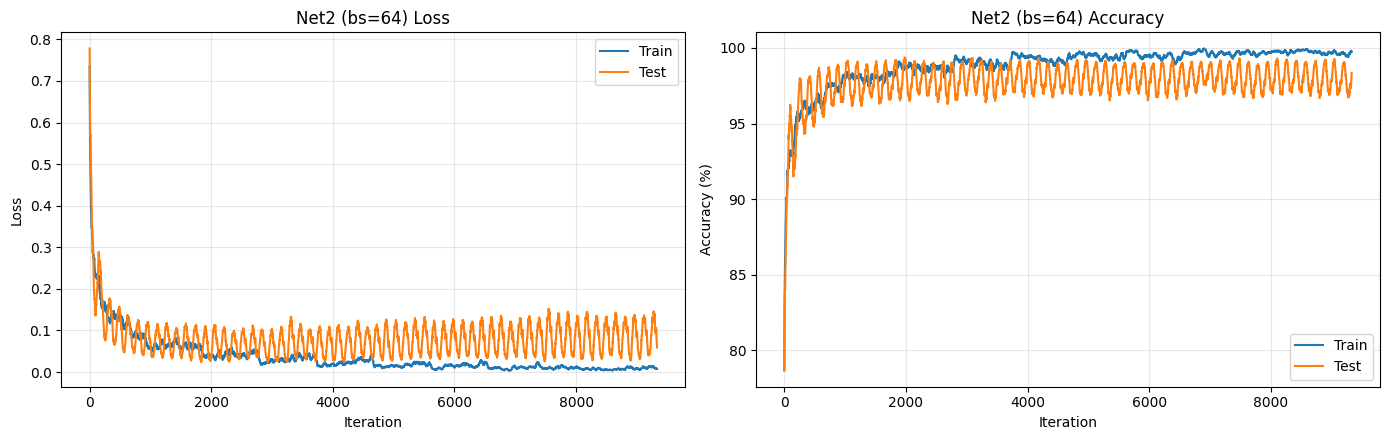

Accuracy: 97.96 %


In [28]:
# Net2
results['arch_net2'] = run_experiment(Net2(), 'Net2 (bs=64)', lr=2e-3, bs=64)

===== Net5 (bs=64) =====
Epoch [1/10] Train Loss: 0.1310 | Train Acc: 95.96% | Test Loss: 0.0497 | Test Acc: 98.35% | Time: 12.8s
Epoch [2/10] Train Loss: 0.0473 | Train Acc: 98.56% | Test Loss: 0.0432 | Test Acc: 98.61% | Time: 12.8s
Epoch [3/10] Train Loss: 0.0332 | Train Acc: 98.99% | Test Loss: 0.0462 | Test Acc: 98.55% | Time: 12.7s
Epoch [4/10] Train Loss: 0.0249 | Train Acc: 99.23% | Test Loss: 0.0536 | Test Acc: 98.37% | Time: 12.8s
Epoch [5/10] Train Loss: 0.0223 | Train Acc: 99.36% | Test Loss: 0.0544 | Test Acc: 98.42% | Time: 12.7s
Epoch [6/10] Train Loss: 0.0181 | Train Acc: 99.44% | Test Loss: 0.0542 | Test Acc: 98.65% | Time: 12.7s
Epoch [7/10] Train Loss: 0.0177 | Train Acc: 99.50% | Test Loss: 0.0653 | Test Acc: 98.71% | Time: 12.7s
Epoch [8/10] Train Loss: 0.0162 | Train Acc: 99.53% | Test Loss: 0.0847 | Test Acc: 98.43% | Time: 12.8s
Epoch [9/10] Train Loss: 0.0162 | Train Acc: 99.56% | Test Loss: 0.0701 | Test Acc: 98.82% | Time: 12.8s
Epoch [10/10] Train Loss: 0.01

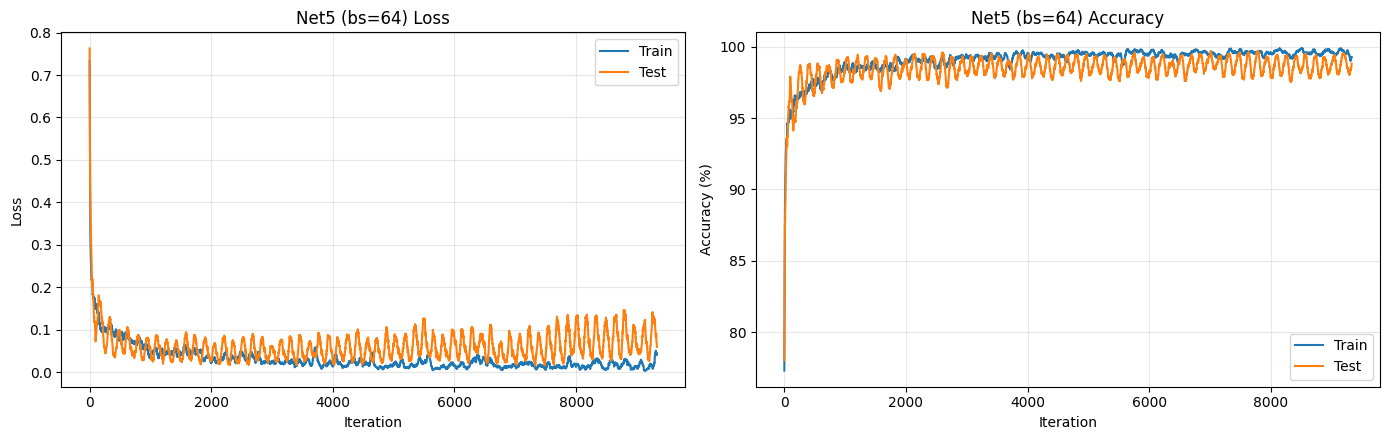

Accuracy: 98.74 %


In [29]:
# Net5
results['arch_net5'] = run_experiment(Net5(), 'Net5 (bs=64)', lr=2e-3, bs=64)

===== FCN (bs=64) =====
Epoch [1/10] Train Loss: 0.2146 | Train Acc: 93.44% | Test Loss: 0.1160 | Test Acc: 96.31% | Time: 11.8s
Epoch [2/10] Train Loss: 0.0986 | Train Acc: 96.98% | Test Loss: 0.0843 | Test Acc: 97.40% | Time: 12.0s
Epoch [3/10] Train Loss: 0.0749 | Train Acc: 97.72% | Test Loss: 0.1047 | Test Acc: 96.90% | Time: 12.0s
Epoch [4/10] Train Loss: 0.0610 | Train Acc: 98.07% | Test Loss: 0.0887 | Test Acc: 97.44% | Time: 12.0s
Epoch [5/10] Train Loss: 0.0536 | Train Acc: 98.33% | Test Loss: 0.0958 | Test Acc: 97.38% | Time: 11.9s
Epoch [6/10] Train Loss: 0.0451 | Train Acc: 98.63% | Test Loss: 0.0967 | Test Acc: 97.64% | Time: 11.8s
Epoch [7/10] Train Loss: 0.0440 | Train Acc: 98.65% | Test Loss: 0.0898 | Test Acc: 97.97% | Time: 12.0s
Epoch [8/10] Train Loss: 0.0394 | Train Acc: 98.80% | Test Loss: 0.1146 | Test Acc: 97.43% | Time: 11.9s
Epoch [9/10] Train Loss: 0.0377 | Train Acc: 98.88% | Test Loss: 0.1024 | Test Acc: 97.91% | Time: 12.0s
Epoch [10/10] Train Loss: 0.039

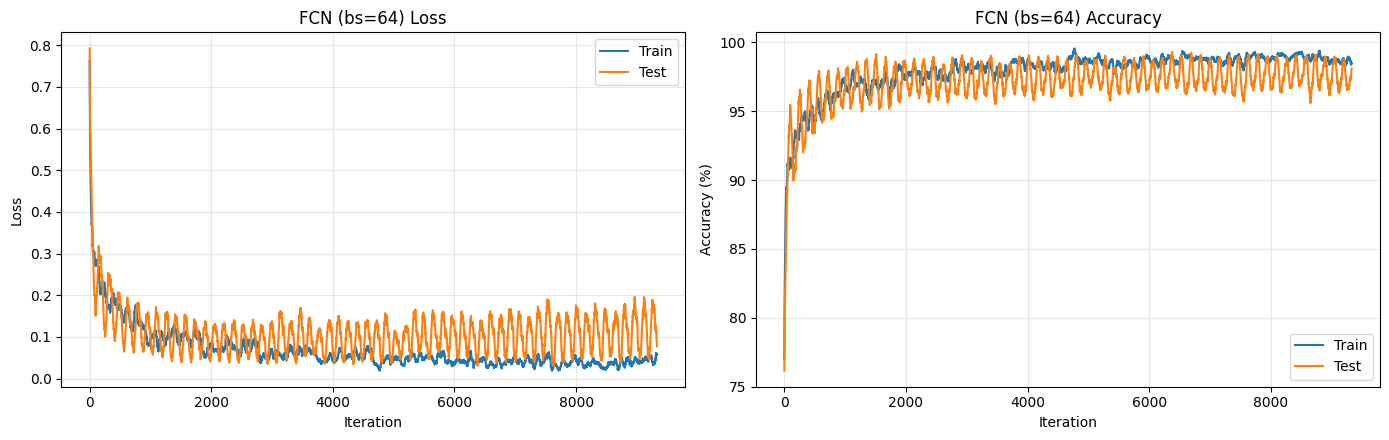

Accuracy: 97.59 %
Net2: final test acc = 97.96%
Net5: final test acc = 98.74%
FCN: final test acc = 97.59%


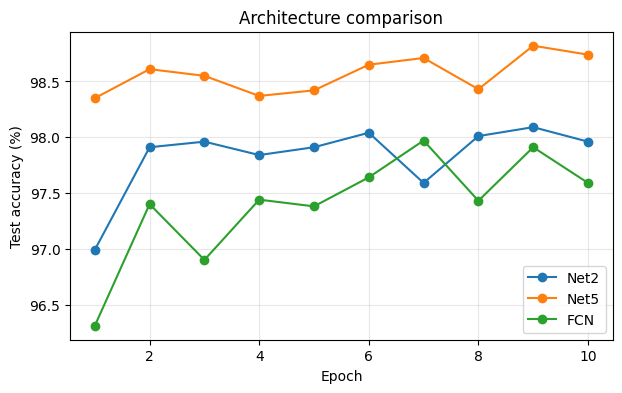

In [30]:
# FCN
results['arch_fcn'] = run_experiment(FCN(), 'FCN (bs=64)', lr=2e-3, bs=64)

# Summary + overlaid test-accuracy curves (per epoch)
plt.figure(figsize=(7, 4))
for k, name in [('arch_net2', 'Net2'), ('arch_net5', 'Net5'), ('arch_fcn', 'FCN')]:
    plt.plot(range(1, len(results[k]['epoch_test_acc']) + 1), results[k]['epoch_test_acc'], marker='o', label=name)
    print(f"{name}: final test acc = {results[k]['final_test_acc']:.2f}%")
plt.xlabel('Epoch'); plt.ylabel('Test accuracy (%)'); plt.title('Architecture comparison'); plt.legend(); plt.grid(alpha=.3)
plt.show()

#### ❓ **Q 5.7.4 Explain which model is better and why. Use your learning curves as well as what you know about model capacity to explain your reasoning.** If you think your results do not reflect the best model, explain which you expect to be best and why.

**Answer:** **Net5 is the best model**: it reaches the highest test accuracy (around 99%, vs ~98% for Net2 and ~97.5–98% for FCN), and its test curve stays highest across epochs.

Why:
- **Capacity where it matters:** Net5 has two convolutional layers. The first learns edges and strokes; the second combines them into larger shapes such as loops and corners. Max-pooling adds tolerance to small shifts. This hierarchy of local features matches the structure of digit images far better than Net2's single conv layer.
- **Inductive bias:** both CNNs share weights across positions, so they learn translation-equivariant features with relatively few weights per feature. The FCN must learn a separate weight for every pixel of every pattern, ignoring the 2-D structure, so it generalises less efficiently even though it has many parameters (~270k).
- **Overfitting check:** Net5 has the most parameters (~12.9M, mostly in fc1), so it can overfit. Its train accuracy runs ahead of test towards the end and test loss may start to creep up. Even so, its test accuracy stays the highest because its features are better. Net2 has a single linear layer on 13,520 conv features and less representational power. FCN shows the clearest train/test gap relative to its accuracy.

If a run doesn't show Net5 on top (it can be close with only a few epochs, or overfit slightly with lr 2e-3), Net5 is still the expected winner. Adding dropout or batch norm (Section 5.8) and a slightly lower learning rate would make the margin clearer.

#### ❓ **Q 5.7.5 Which model converges to a minimum faster? Why? What hyperparameters would you tune in order to get a model to converge faster?**

**Answer:** In **terms of iterations/epochs, the CNNs, especially Net5, converge fastest**: their test accuracy is already ~98% after the first epoch, and the loss reaches its plateau quickly. Convolutional features with shared weights are a strong prior for images, so far fewer updates are needed to find good features. The FCN starts lower and needs more epochs to plateau. In **wall-clock time per epoch**, however, the FCN is fastest because it has the least computation, and Net5 is the slowest because of its larger convolutions and the 12,544×1024 FC layer.

Hyperparameters to tune for faster convergence:
- **Learning rate** (the biggest lever): increase it as far as stability allows, and use warm-up plus a decay schedule (step, cosine or OneCycle).
- **Optimizer:** Adam/AdamW or SGD with momentum ~0.9 (or Nesterov) instead of plain SGD.
- **Batch size:** smaller batches give more updates per epoch, larger batches give faster epochs. Scale the lr with batch size.
- **Weight initialisation** (Kaiming for ReLU) and **batch normalisation**, which allow higher learning rates and better-conditioned optimisation.
- Input normalisation (already done) and, for deeper models, residual connections.

#### ❓ **Q 5.7.6 Explain the purpose of the pooling layer**

**Answer:** A pooling layer downsamples feature maps by summarising each small window, e.g. taking the maximum (max-pooling) or average of each 2×2 region with stride 2. Its purposes:

1. **Dimensionality / compute reduction:** a 2×2 pool cuts the spatial size by 4×. In Net5 this shrinks 28×28 maps to 14×14, which reduces the cost of later conv layers and the number of FC parameters (without the pool, fc1 would have 4× more weights).
2. **Translation invariance:** max-pooling keeps the strongest response in a neighbourhood regardless of its exact position, so the network becomes robust to small shifts and distortions of the input.
3. **Larger receptive field:** after pooling, each unit in the next conv layer covers a bigger region of the original image, which lets deeper layers capture more global shapes.
4. **Mild regularisation:** discarding some spatial detail, and having no learnable parameters, reduces the risk of overfitting.

#### ❓ **Q 5.7.7  Is it possible for a model to have a smaller final loss, even if it has worse test accuracy.**

**Answer:** **Yes.** Cross-entropy loss and accuracy measure different things. Accuracy only checks whether the arg-max class is right. Loss also depends on *how confident* the predictions are.

- Model A can be right on more samples but with low confidence (e.g. p = 0.4 for the true class) and very confidently wrong on a few hard samples. Those confident mistakes produce huge −log(p) terms, so its average loss is high even though accuracy is better.
- Model B can get a few more samples wrong but put high probability on the correct class for most others and never be extremely confidently wrong, giving a lower average loss despite lower accuracy.

The same mismatch also shows up between training loss and test accuracy: an overfit model can have a very small **training** loss but worse test accuracy than a less-fit model, because it has memorised the training data. That is why we judge models on held-out metrics and look at both loss and accuracy.

#### ❓ **Q 5.7.8 Explain the difference between the CNN models and FCN.**

**Answer:**

| | CNN (Net2 / Net5) | FCN |
|---|---|---|
| Input | Keeps the 2-D image (C×H×W) | Flattens the image into a 784-vector, discarding spatial layout |
| Connectivity | **Local**: each neuron sees only a small k×k patch (receptive field) | **Global**: every neuron connects to every input pixel |
| Weight sharing | The same filter slides over the whole image, so features are detected anywhere (**translation equivariance**, plus pooling for invariance) | No sharing: a pattern must be learned separately for each position |
| Parameters | Few per layer (Net5 conv1: 32×1×5×5 = 800 weights) | Many per layer (fc1 alone: 784×256 ≈ 200k) |
| Features | **Hierarchical**: edges → strokes → shapes | Learns global templates and has no notion of neighbouring pixels |
| Result on images | Better accuracy and generalisation with fewer, better-used parameters, and robust to small shifts | Works on MNIST because digits are centred and small, but generalises worse and scales poorly to large images |

In short, a CNN builds the spatial structure of images into its architecture (locality and weight sharing), whereas an FCN treats pixels as an unordered list of features and must learn all spatial relationships from data.


---



### **5.8 Batch Normalization**

Choose the model that performs the best (`Net`, `Net2`, `Net5`, `FCN`). Add batch normalization layers where you see fit. Repeat and train and plot learning curves.



===== Net5 + BatchNorm (bs=64) =====
Epoch [1/10] Train Loss: 0.0955 | Train Acc: 97.03% | Test Loss: 0.0406 | Test Acc: 98.64% | Time: 13.0s
Epoch [2/10] Train Loss: 0.0408 | Train Acc: 98.69% | Test Loss: 0.0300 | Test Acc: 99.04% | Time: 13.1s
Epoch [3/10] Train Loss: 0.0293 | Train Acc: 99.06% | Test Loss: 0.0460 | Test Acc: 98.50% | Time: 13.0s
Epoch [4/10] Train Loss: 0.0249 | Train Acc: 99.17% | Test Loss: 0.0334 | Test Acc: 99.05% | Time: 13.2s
Epoch [5/10] Train Loss: 0.0211 | Train Acc: 99.30% | Test Loss: 0.0302 | Test Acc: 99.01% | Time: 13.1s
Epoch [6/10] Train Loss: 0.0165 | Train Acc: 99.47% | Test Loss: 0.0312 | Test Acc: 99.16% | Time: 13.0s
Epoch [7/10] Train Loss: 0.0153 | Train Acc: 99.49% | Test Loss: 0.0288 | Test Acc: 99.21% | Time: 13.0s
Epoch [8/10] Train Loss: 0.0126 | Train Acc: 99.57% | Test Loss: 0.0416 | Test Acc: 99.03% | Time: 13.1s
Epoch [9/10] Train Loss: 0.0103 | Train Acc: 99.64% | Test Loss: 0.0377 | Test Acc: 99.10% | Time: 13.2s
Epoch [10/10] Trai

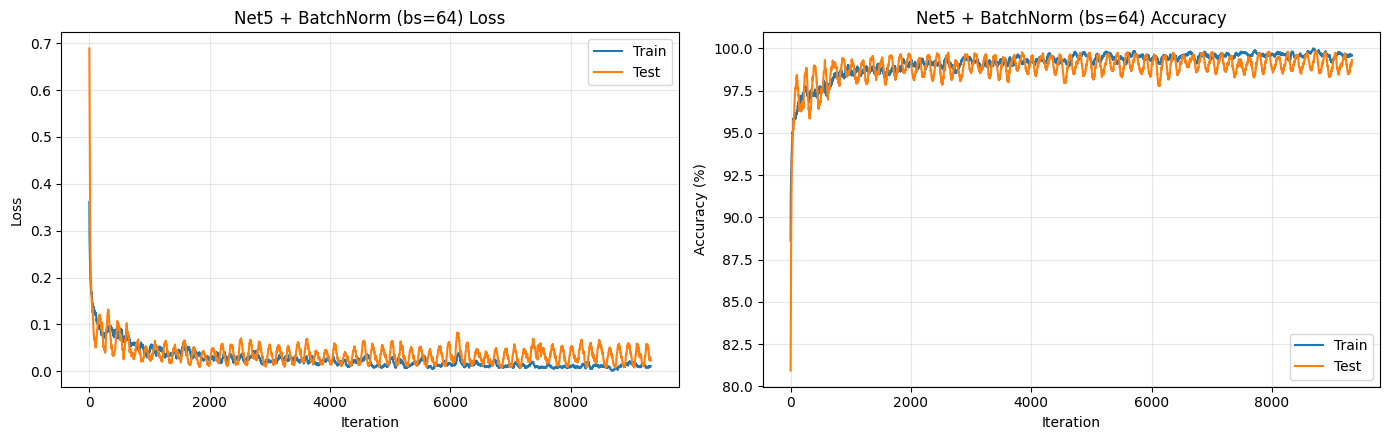

Accuracy: 99.24 %


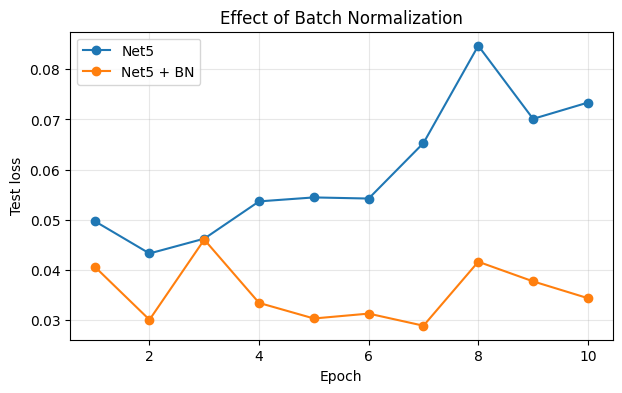

Net5: 98.74%  |  Net5+BN: 99.24%


In [31]:
# Best model: Net5 -> add BatchNorm after each conv (BatchNorm2d) and after fc1 (BatchNorm1d)
class Net5BN(nn.Module):
    def __init__(self, num_classes=10):
        super(Net5BN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=1, padding=2)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 14 * 14, 1024)
        self.bn3 = nn.BatchNorm1d(1024)
        self.fc2 = nn.Linear(1024, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.pool(self.relu(self.bn1(self.conv1(x))))
        out = self.relu(self.bn2(self.conv2(out)))
        out = out.view(out.size(0), -1)
        out = self.relu(self.bn3(self.fc1(out)))
        return self.fc2(out)

results['net5_bn'] = run_experiment(Net5BN(), 'Net5 + BatchNorm (bs=64)', lr=2e-3, bs=64)

plt.figure(figsize=(7, 4))
for k, name in [('arch_net5', 'Net5'), ('net5_bn', 'Net5 + BN')]:
    plt.plot(range(1, len(results[k]['epoch_test_loss']) + 1), results[k]['epoch_test_loss'], marker='o', label=name)
plt.xlabel('Epoch'); plt.ylabel('Test loss'); plt.title('Effect of Batch Normalization'); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(f"Net5: {results['arch_net5']['final_test_acc']:.2f}%  |  Net5+BN: {results['net5_bn']['final_test_acc']:.2f}%")

#### ❓ **Q 5.8 Explain the purpose of the batch normalization layers,and how they affect training.**

**Answer:** Batch normalisation normalises a layer's pre-activations over the mini-batch to zero mean and unit variance, `x̂ = (x − μ_B) / √(σ²_B + ε)`, then applies a learnable scale and shift, `y = γ·x̂ + β`, so the network can still represent any distribution it needs. At test time it uses running averages of μ and σ collected during training.

Effects on training:
- **Stabler, faster optimisation:** each layer's inputs keep a consistent scale even as earlier layers change (reducing "internal covariate shift") and the loss landscape becomes smoother. Gradients stay well-scaled, so higher learning rates can be used and the model converges in fewer epochs. In the plot above, the BN model's loss drops faster in the first epoch(s).
- **Less sensitivity to initialisation and learning rate:** a badly scaled layer is automatically renormalised.
- **Regularisation:** because μ and σ are estimated per mini-batch, each sample's output depends slightly on the other samples in the batch. This noise acts like a mild regulariser, so the train/test gap is usually smaller (often reducing the need for dropout).
- **Caveats:** it depends on batch statistics, so it behaves poorly with very small batches, and the model must be switched to `model.eval()` at test time (our `evaluate` and `test_accuracy` functions do this).

For Net5, BN typically gives the same or slightly higher test accuracy (~99%+) with faster, smoother convergence, and lets the 12.9M-parameter model overfit less.

---
---

# End of Phase 1 😊🥳